# Démo plutovizu

Tour d'horizon de l'API chaînable : chaque méthode retourne le graphique, on enchaîne les appels et on termine par `.show()`.

Le thème **editorial** est appliqué dès `import plutovizu` ; `set_theme('nom')` en choisit un autre, `set_theme(None)` revient au style matplotlib et `set_theme()` remet editorial. La [documentation](https://mr-kam.github.io/plutovizu/) présente les 80 graphiques.

In [1]:
import tempfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from plutovizu import (Chart, get_fonts, list_themes, set_theme, texture_class,
                       theme_context)

## Données d'exemple

In [2]:
rng = np.random.default_rng(42)
n = 120
jours = np.arange(n)
effet_categorie = {'A': 150, 'B': -80, 'C': 40, 'D': -150}

ventes = pd.DataFrame({
    'date': pd.date_range('2024-01-01', periods=n, freq='D'),
    'categorie': rng.choice(list(effet_categorie), n),
    'temperature': rng.normal(27, 4, n).round(1),
})
# tendance + cycle mensuel + effet de la catégorie + bruit
ventes['ventes'] = (np.linspace(900, 1300, n) + 120 * np.sin(jours * 2 * np.pi / 30)
                    + ventes['categorie'].map(effet_categorie) + rng.normal(0, 40, n))
ventes['profit'] = ventes['ventes'] * 0.18 + rng.normal(0, 15, n)
ventes['visiteurs'] = (20 + 2.2 * ventes['temperature'] + rng.normal(0, 6, n)).round().astype(int)
ventes.head()

,date,categorie,temperature,ventes,profit,visiteurs
0,2024-01-01,A,23.5,1045.254467,161.794977,71
1,2024-01-02,D,30.9,789.743793,147.073815,96
2,2024-01-03,C,20.3,1047.771156,214.509061,65
3,2024-01-04,B,25.7,909.393564,140.682920,72
4,2024-01-05,B,27.7,906.185668,176.070840,77


## 1. Courbes

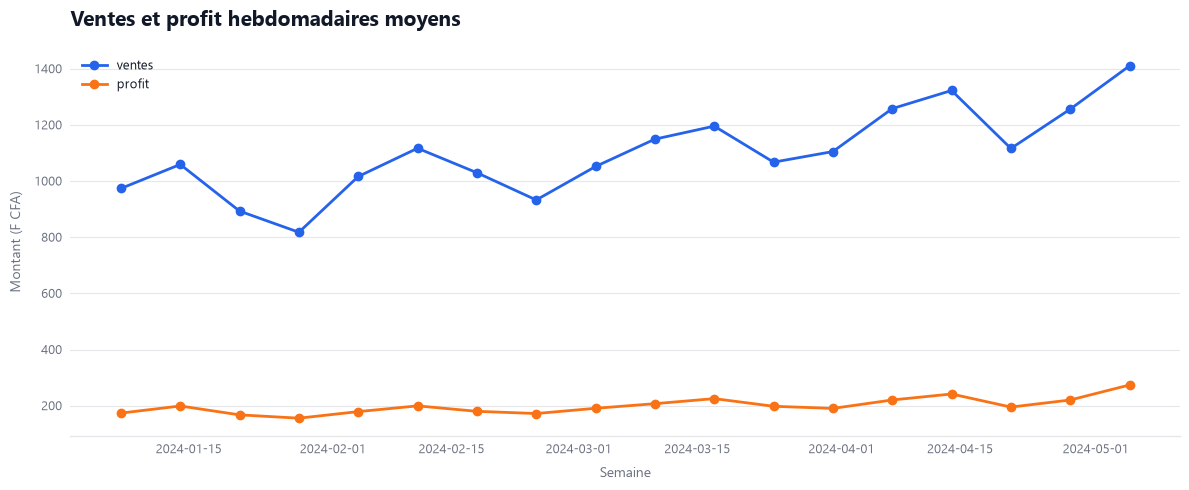

In [3]:
hebdo = ventes.resample('W', on='date')[['ventes', 'profit']].mean().reset_index()

(Chart(hebdo, figsize=(12, 5))
    .line('date', ['ventes', 'profit'])
    .title('Ventes et profit hebdomadaires moyens')
    .labels(xlabel='Semaine', ylabel='Montant (F CFA)')
    .grid()
    .set_legend()
    .tight_layout()
    .show())

## 2. Barres

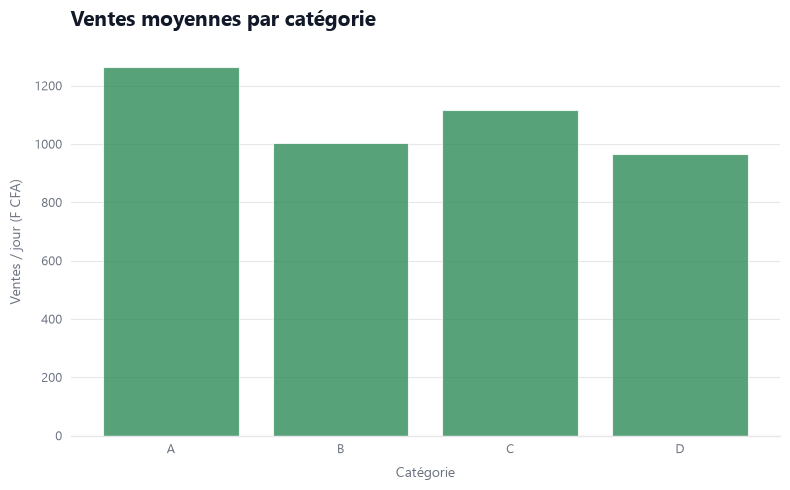

In [4]:
par_categorie = ventes.groupby('categorie', as_index=False)['ventes'].mean()

(Chart(par_categorie, figsize=(8, 5))
    .bar('categorie', 'ventes', color='seagreen')
    .title('Ventes moyennes par catégorie')
    .labels(xlabel='Catégorie', ylabel='Ventes / jour (F CFA)')
    .tight_layout()
    .show())

Plusieurs colonnes `y` donnent des barres groupées, ou empilées avec `stacked=True` ; `show_values=True` écrit les valeurs.

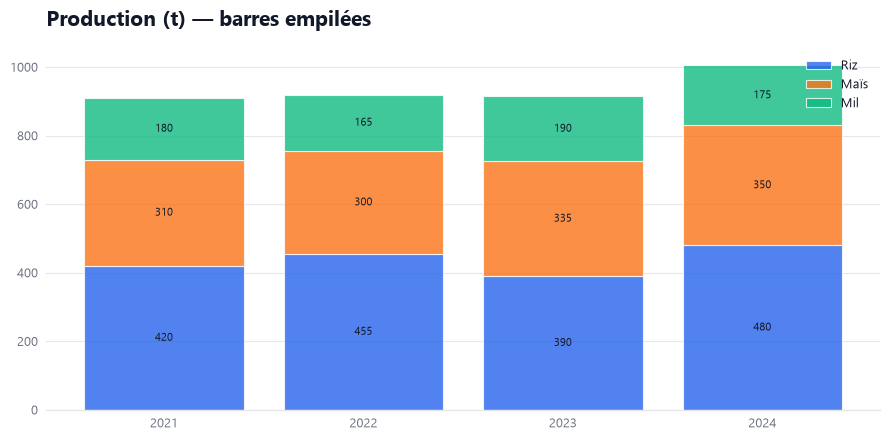

In [5]:
production = pd.DataFrame({'annee': ['2021', '2022', '2023', '2024'],
                           'Riz': [420, 455, 390, 480], 'Maïs': [310, 300, 335, 350],
                           'Mil': [180, 165, 190, 175]})

(Chart(production, figsize=(9, 4.5))
    .bar('annee', ['Riz', 'Maïs', 'Mil'], stacked=True, show_values=True)
    .title('Production (t) — barres empilées')
    .tight_layout()
    .show())

## 3. Nuage de points

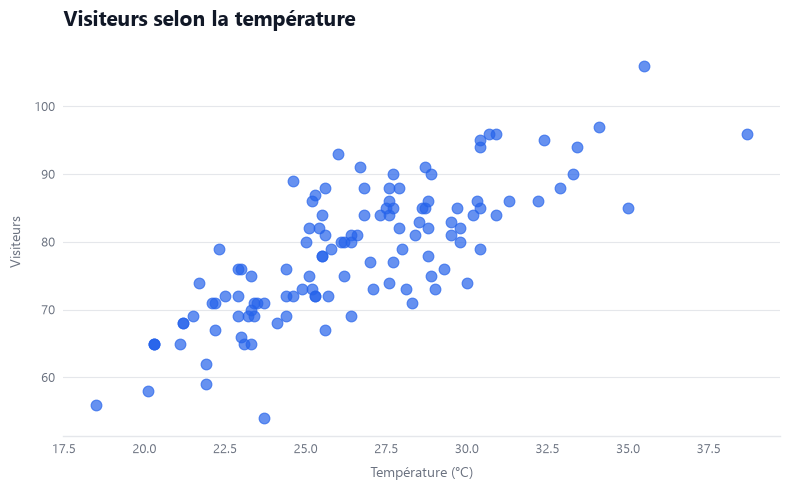

In [6]:
(Chart(ventes, figsize=(8, 5))
    .scatter('temperature', 'visiteurs', size=60)
    .title('Visiteurs selon la température')
    .labels(xlabel='Température (°C)', ylabel='Visiteurs')
    .grid()
    .tight_layout()
    .show())

## 4. Diagramme ombrothermique

Échelle de Gaussen (p = 2T) : un mois est sec quand les précipitations sont inférieures au double de la température.

Analyse des périodes sèches et humides:
Jan: PÉRIODE SÈCHE - Précip: 16.0mm < Seuil: 48.2mm
Fév: PÉRIODE SÈCHE - Précip: 23.9mm < Seuil: 52.2mm
Mar: Période humide - Précip: 86.7mm ≥ Seuil: 53.2mm
Avr: Période humide - Précip: 116.7mm ≥ Seuil: 53.0mm
Mai: Période humide - Précip: 92.9mm ≥ Seuil: 52.2mm
Juin: Période humide - Précip: 147.8mm ≥ Seuil: 50.0mm
Juil: Période humide - Précip: 143.2mm ≥ Seuil: 47.8mm
Août: Période humide - Précip: 215.8mm ≥ Seuil: 47.8mm
Sep: Période humide - Précip: 167.1mm ≥ Seuil: 48.6mm
Oct: Période humide - Précip: 109.4mm ≥ Seuil: 49.6mm
Nov: PÉRIODE SÈCHE - Précip: 30.3mm < Seuil: 49.8mm
Déc: PÉRIODE SÈCHE - Précip: 33.0mm < Seuil: 47.4mm

Résumé: 4 mois secs sur 12 mois


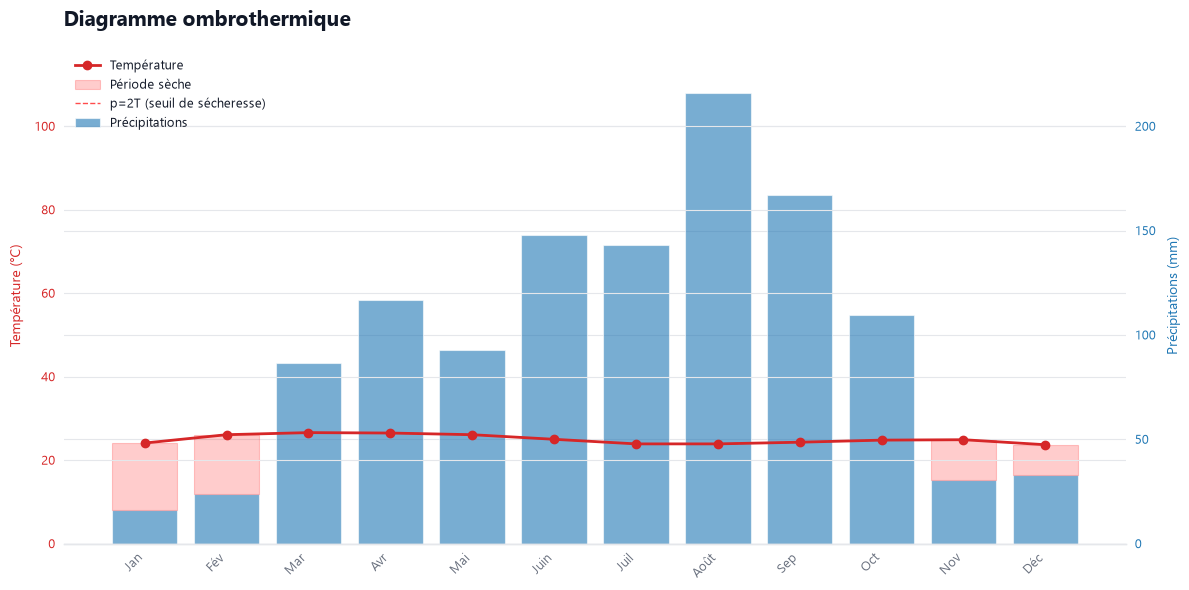

In [7]:
climat = pd.DataFrame({
    'Mois': ['Jan', 'Fév', 'Mar', 'Avr', 'Mai', 'Juin',
             'Juil', 'Août', 'Sep', 'Oct', 'Nov', 'Déc'],
    'Température (°C)': [24.1, 26.1, 26.6, 26.5, 26.1, 25.0,
                         23.9, 23.9, 24.3, 24.8, 24.9, 23.7],
    'Précipitations (mm)': [16, 23.9, 86.7, 116.7, 92.9, 147.8,
                            143.2, 215.8, 167.1, 109.4, 30.3, 33],
})
cols = ('Mois', 'Température (°C)', 'Précipitations (mm)')

(Chart(climat, figsize=(12, 6))
    .ombrothermic(*cols)
    .title('Diagramme ombrothermique')
    .print_ombrothermic_analysis(*cols)
    .tight_layout()
    .show())

## 5. Sciences de la nature

Un essai agronomique fictif : trois variétés de riz, cinq doses d'azote, quatre blocs.

In [8]:
rng = np.random.default_rng(3)
lignes = []
for variete, gain in [('Sahel-108', 0.0), ('IR-841', 0.7), ('Nerica-4', 1.3)]:
    for dose in [0, 30, 60, 90, 120]:
        for bloc in range(1, 5):
            lignes.append({'variete': variete, 'dose': dose, 'bloc': bloc,
                           'rendement': 2.5 + gain + 0.035 * dose - 0.00018 * dose ** 2
                                        + rng.normal(0, 0.3)})
essai = pd.DataFrame(lignes)
essai.head()

,variete,dose,bloc,rendement
0,Sahel-108,0,1,3.112276
1,Sahel-108,0,2,1.733300
2,Sahel-108,0,3,2.625430
3,Sahel-108,0,4,2.329669
4,Sahel-108,30,1,3.252205


### Régression : courbe de réponse à l'azote

Ajustement polynomial, bande de confiance à 95 %, équation et R².

{'coefs': array([-2.07043582e-04,  3.73229013e-02,  3.16931512e+00]), 'r2': np.float64(0.4819982877068384), 'p': None, 'n': 60}


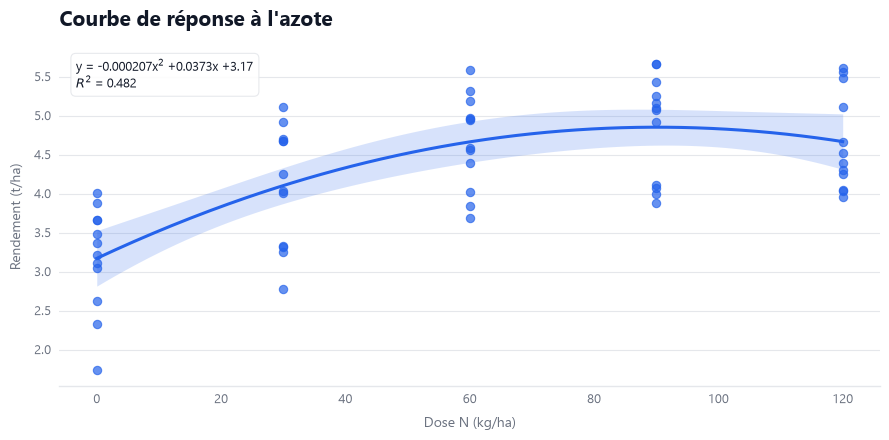

In [9]:
chart = (Chart(essai, figsize=(9, 4.5))
    .regression('dose', 'rendement', order=2)
    .title("Courbe de réponse à l'azote")
    .labels(xlabel='Dose N (kg/ha)', ylabel='Rendement (t/ha)')
    .tight_layout())
print(chart.regression_stats)
chart.show()

### Moyennes ± erreur et lettres de Tukey

Deux barres qui partagent une lettre ne diffèrent pas significativement (Tukey HSD, α = 5 %). Avec `hue`, les variétés sont comparées à l'intérieur de chaque dose.

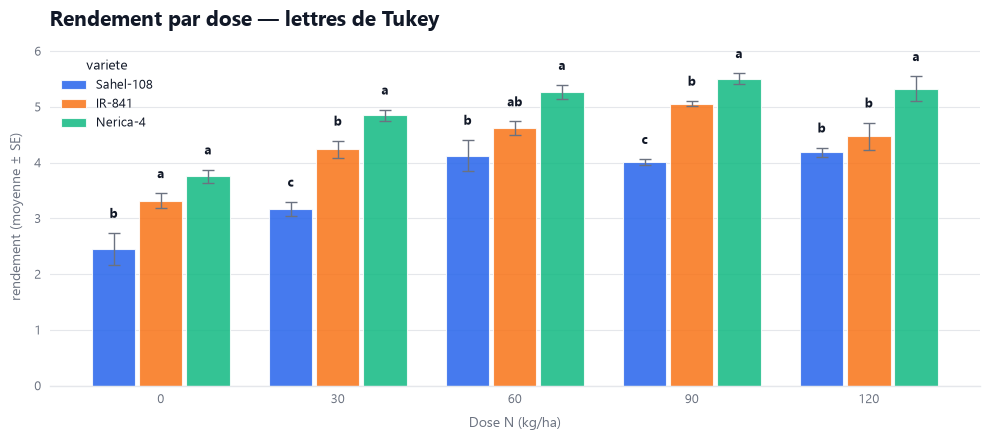

{(0, 'Sahel-108'): 'b',
 (0, 'IR-841'): 'a',
 (0, 'Nerica-4'): 'a',
 (30, 'Sahel-108'): 'c',
 (30, 'IR-841'): 'b',
 (30, 'Nerica-4'): 'a',
 (60, 'Sahel-108'): 'b',
 (60, 'IR-841'): 'ab',
 (60, 'Nerica-4'): 'a',
 (90, 'Sahel-108'): 'c',
 (90, 'IR-841'): 'b',
 (90, 'Nerica-4'): 'a',
 (120, 'Sahel-108'): 'b',
 (120, 'IR-841'): 'b',
 (120, 'Nerica-4'): 'a'}

In [10]:
chart = (Chart(essai, figsize=(10, 4.5))
    .mean_bar('dose', 'rendement', hue='variete', letters=True)
    .title('Rendement par dose — lettres de Tukey')
    .labels(xlabel='Dose N (kg/ha)')
    .tight_layout())
chart.show()
chart.tukey_letters

### Interaction et normalité des résidus

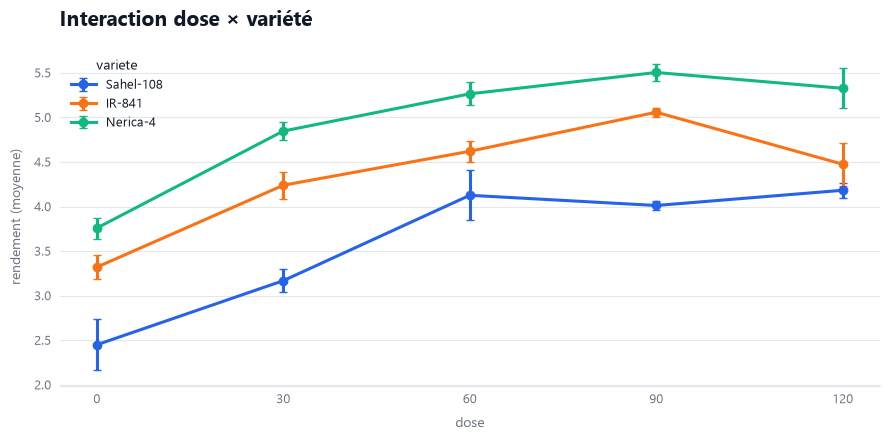

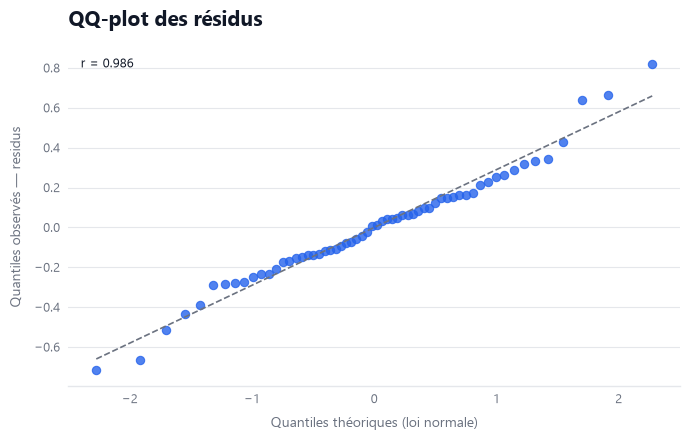

In [11]:
(Chart(essai, figsize=(9, 4.5))
    .interaction('dose', 'variete', 'rendement')
    .title('Interaction dose × variété')
    .tight_layout()
    .show())

essai['residus'] = essai['rendement'] - essai.groupby(['variete', 'dose'])['rendement'].transform('mean')
(Chart(essai, figsize=(7, 4.5))
    .qqplot('residus')
    .title('QQ-plot des résidus')
    .tight_layout()
    .show())

### ACP, dendrogramme et clustermap

Cinq caractères mesurés sur 20 variétés.

Variance expliquée (%) : [69.3 15.7  8.1]


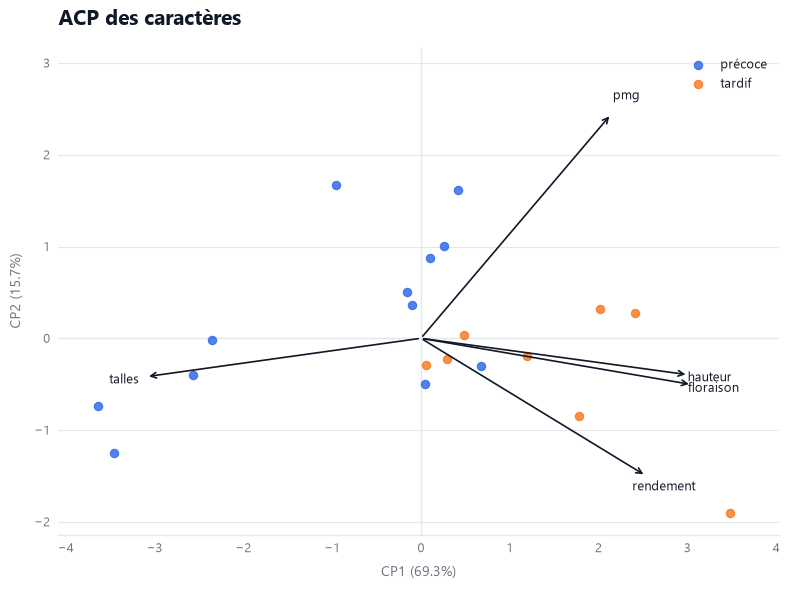

In [12]:
rng = np.random.default_rng(7)
n = 20
precocite = rng.normal(size=n)
caracteres = pd.DataFrame({
    'variete': [f'V{i:02d}' for i in range(n)],
    'cycle': np.where(precocite > 0, 'tardif', 'précoce'),
    'hauteur': 95 + 12 * precocite + rng.normal(0, 5, n),
    'floraison': 85 + 10 * precocite + rng.normal(0, 3, n),
    'talles': 12 - 2 * precocite + rng.normal(0, 1, n),
    'pmg': 25 + rng.normal(0, 2.5, n),
    'rendement': 4.5 + 0.5 * precocite + rng.normal(0, 0.4, n),
})

chart = Chart(caracteres, figsize=(8, 6)).pca_biplot(group='cycle').title('ACP des caractères').tight_layout()
print('Variance expliquée (%) :', (chart.pca['explained_variance_ratio'][:3] * 100).round(1))
chart.show()

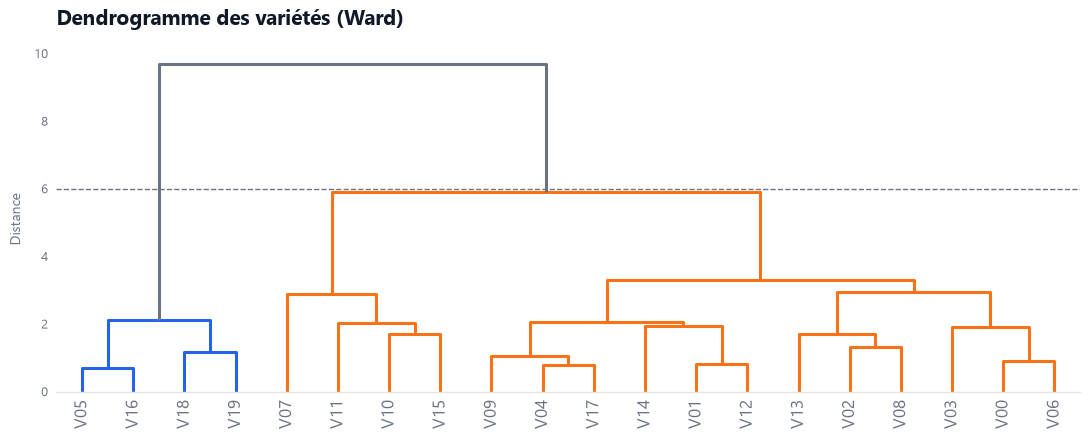

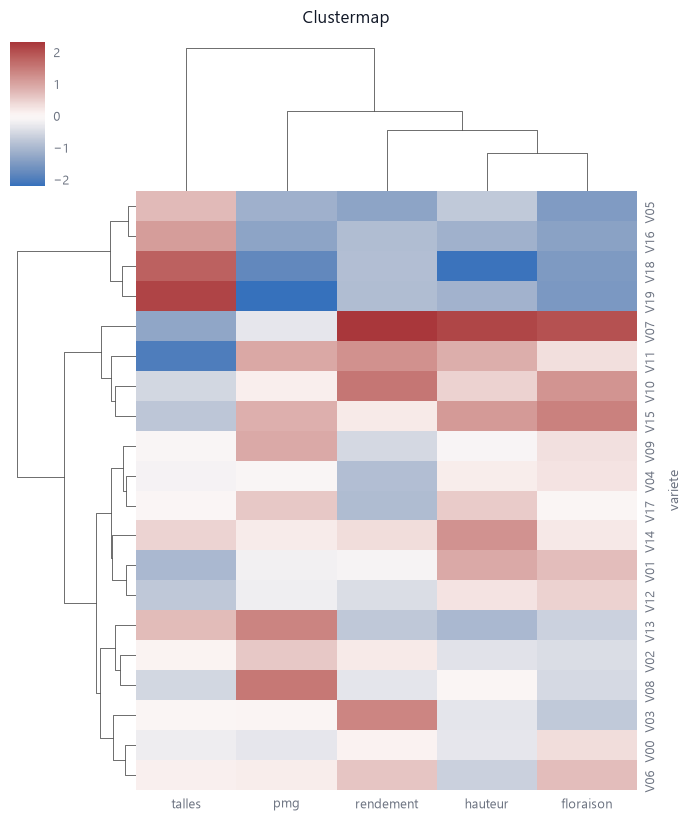

In [13]:
(Chart(caracteres, figsize=(11, 4.5))
    .dendrogram(labels='variete', color_threshold=6)
    .title('Dendrogramme des variétés (Ward)')
    .tight_layout()
    .show())

Chart(caracteres, figsize=(7, 8)).clustermap(labels='variete').title('Clustermap').show()

### Triangle des textures du sol (USDA)

`soil_texture` trace les 12 classes ; `texture_class` classe les échantillons sans tracer.

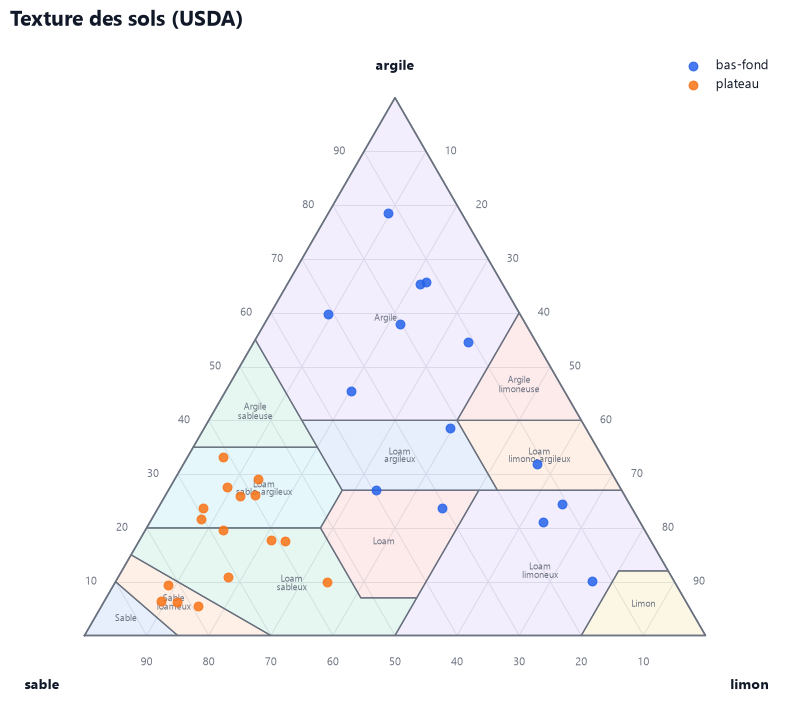

texture
Argile                  7
Loam sablo-argileux     7
Loam sableux            5
Sable loameux           4
Loam limoneux           3
Loam                    2
Loam argileux           1
Loam limono-argileux    1
Name: count, dtype: int64

In [14]:
rng = np.random.default_rng(11)
sols = pd.DataFrame({'zone': rng.choice(['bas-fond', 'plateau'], 30)})
sols['sable'] = np.where(sols['zone'] == 'plateau', rng.uniform(55, 85, 30), rng.uniform(10, 45, 30))
sols['argile'] = rng.uniform(5, 100 - sols['sable'] - 5)
sols['limon'] = 100 - sols['sable'] - sols['argile']

chart = (Chart(sols, figsize=(8, 7.5))
    .soil_texture('sable', 'limon', 'argile', group='zone')
    .title('Texture des sols (USDA)')
    .tight_layout())
chart.show()
chart.texture_classes.value_counts()

In [15]:
texture_class(40, 40, 20), texture_class(10, 80, 10), texture_class(20, 20, 60)

('Loam', 'Limon', 'Argile')

### Cercles imbriqués (circle packing)

Un cercle par culture, d'aire proportionnelle à la surface, regroupé par famille (calcul par circlify). `chart.circles` contient la position et le rayon de chaque cercle.

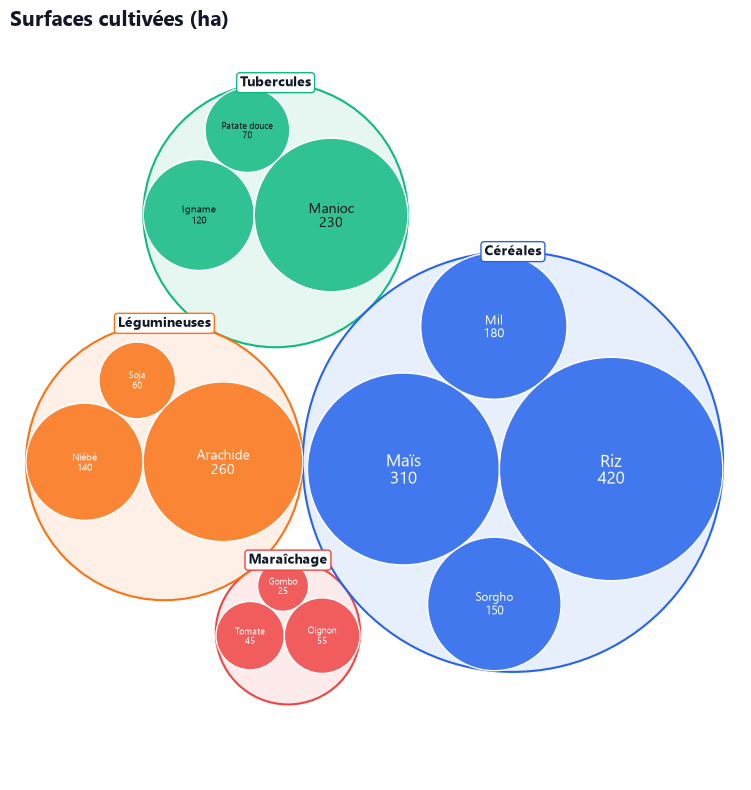

In [16]:
cultures = pd.DataFrame({
    'famille': ['Céréales'] * 4 + ['Légumineuses'] * 3 + ['Tubercules'] * 3 + ['Maraîchage'] * 3,
    'culture': ['Riz', 'Maïs', 'Mil', 'Sorgho', 'Niébé', 'Arachide', 'Soja',
                'Manioc', 'Igname', 'Patate douce', 'Tomate', 'Oignon', 'Gombo'],
    'surface': [420, 310, 180, 150, 140, 260, 60, 230, 120, 70, 45, 55, 25],
})

(Chart(cultures, figsize=(8, 8))
    .circle_packing('surface', labels='culture', group='famille', show_values=True)
    .title('Surfaces cultivées (ha)')
    .tight_layout()
    .show())

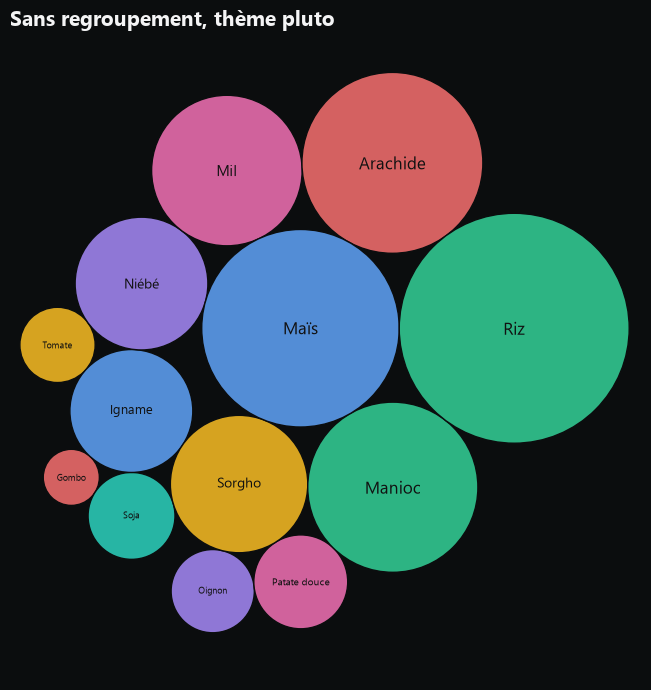

In [17]:
with theme_context('pluto'):
    (Chart(cultures, figsize=(7, 7))
        .circle_packing('surface', labels='culture')
        .title('Sans regroupement, thème pluto')
        .tight_layout()
        .show())

## 6. Analyse qualitative

Réponses ouvertes, entretiens et questionnaires d'opinion.

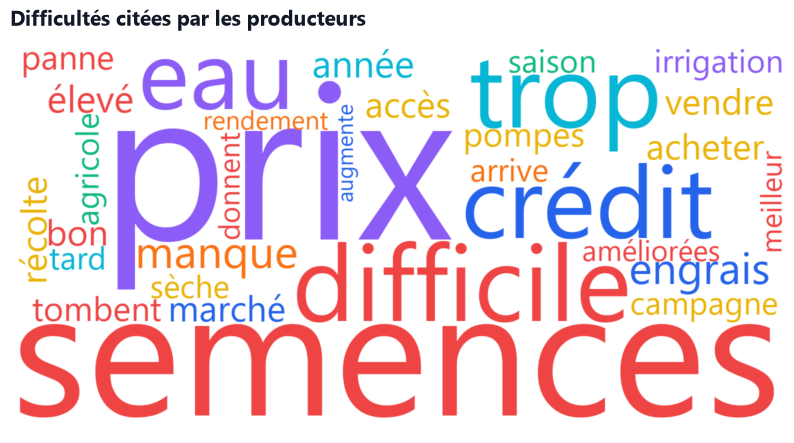

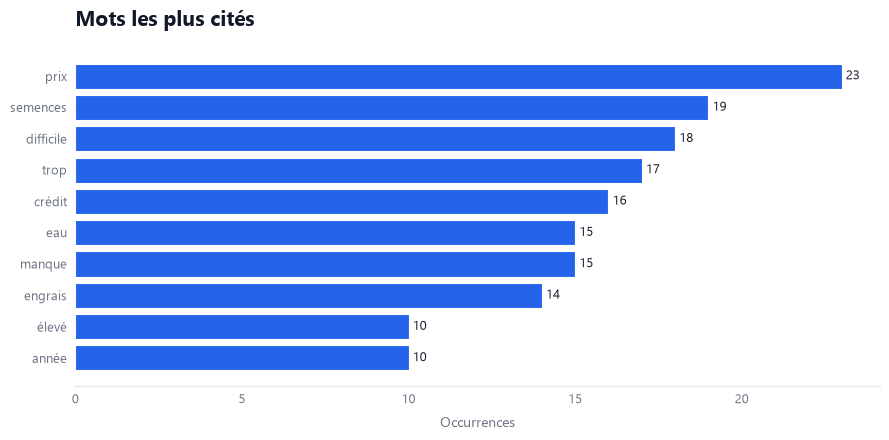

In [18]:
temoignages = [
    "Le prix de l'engrais est trop élevé cette année",
    "Manque d'eau pour l'irrigation en saison sèche",
    "Accès au crédit difficile pour acheter les semences",
    "Les semences améliorées donnent un meilleur rendement",
    "Le prix des semences et de l'engrais augmente encore",
    "L'eau manque et les pompes tombent souvent en panne",
    "Le crédit agricole arrive trop tard pour la campagne",
    "Difficile de vendre la récolte à bon prix au marché",
]
rng = np.random.default_rng(5)
enquete = pd.DataFrame({'reponse': rng.choice(temoignages, 60)})

(Chart(enquete, figsize=(10, 5))
    .word_cloud('reponse')
    .title('Difficultés citées par les producteurs')
    .show())

(Chart(enquete, figsize=(9, 4.5))
    .word_frequency('reponse', top=10)
    .title('Mots les plus cités')
    .tight_layout()
    .show())

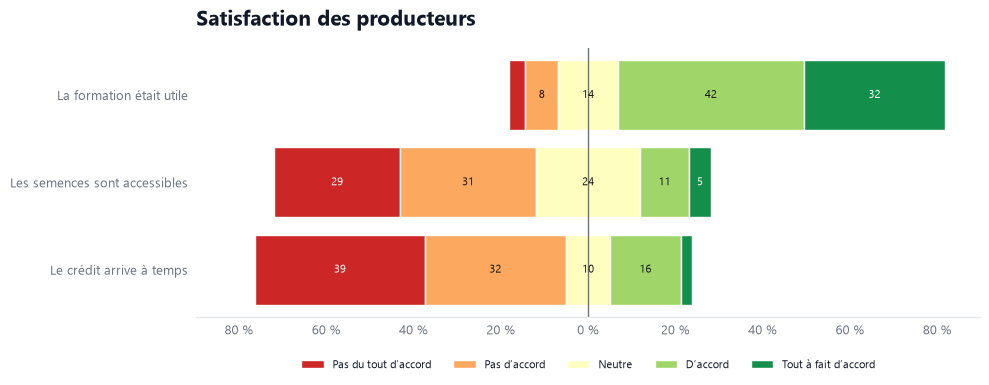

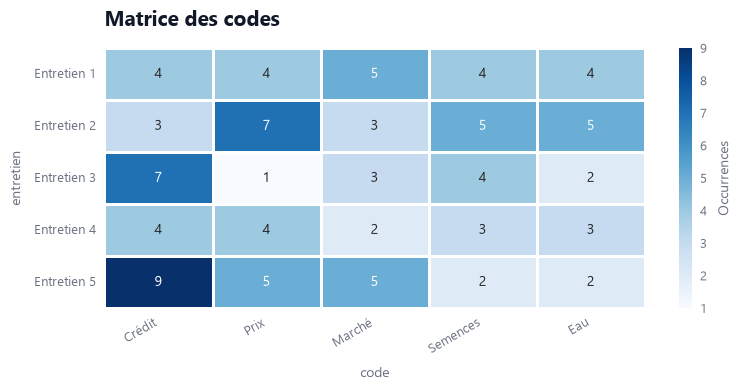

In [19]:
echelle = ['Pas du tout d’accord', 'Pas d’accord', 'Neutre', 'D’accord', 'Tout à fait d’accord']
opinions = pd.DataFrame({q: rng.choice(echelle, 80, p=p) for q, p in {
    'La formation était utile': [.05, .10, .15, .40, .30],
    'Les semences sont accessibles': [.25, .30, .20, .15, .10],
    'Le crédit arrive à temps': [.35, .30, .15, .15, .05],
}.items()})

(Chart(opinions, figsize=(10, 4))
    .likert(list(opinions.columns), order=echelle)
    .title('Satisfaction des producteurs')
    .tight_layout()
    .show())

segments = pd.DataFrame({
    'entretien': rng.choice([f'Entretien {i}' for i in range(1, 6)], 100),
    'code': rng.choice(['Eau', 'Prix', 'Crédit', 'Semences', 'Marché'], 100),
})
(Chart(segments, figsize=(8, 4))
    .code_matrix('entretien', 'code')
    .title('Matrice des codes')
    .tight_layout()
    .show())

## 7. Autres types de graphiques (catalogue matplotlib)

Une sélection : bande, frise, rose des vents, anneau, carte de champ, surface 3D, ellipses.

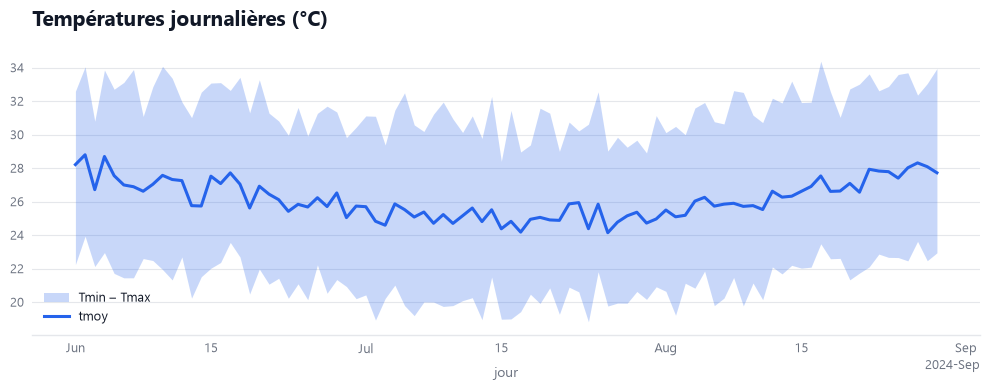

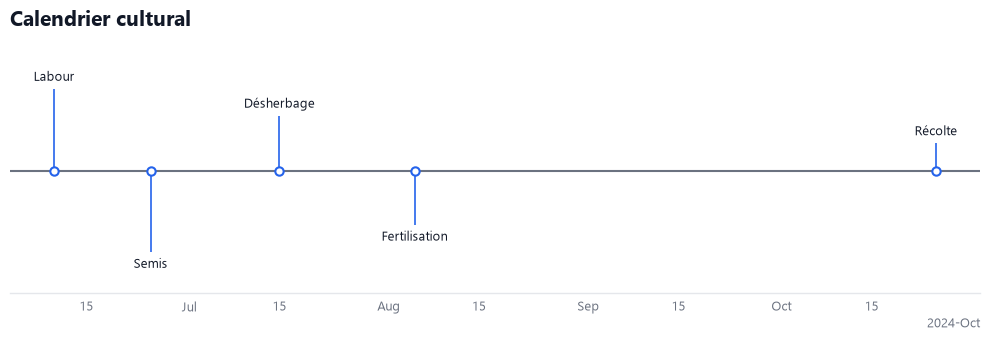

In [20]:
rng = np.random.default_rng(21)
t = np.arange(90)
meteo = pd.DataFrame({'jour': pd.date_range('2024-06-01', periods=90, freq='D'),
                      'tmoy': 28 - 3 * np.sin(t / 90 * np.pi) + rng.normal(0, 0.6, 90)})
meteo['tmin'] = meteo['tmoy'] - rng.uniform(4, 6, 90)
meteo['tmax'] = meteo['tmoy'] + rng.uniform(4, 7, 90)

(Chart(meteo, figsize=(10, 4))
    .band('jour', 'tmin', 'tmax', y='tmoy', label='Tmin – Tmax')
    .title('Températures journalières (°C)')
    .tight_layout()
    .show())

calendrier = pd.DataFrame({
    'date': pd.to_datetime(['2024-06-10', '2024-06-25', '2024-07-15', '2024-08-05', '2024-10-25']),
    'etape': ['Labour', 'Semis', 'Désherbage', 'Fertilisation', 'Récolte']})
(Chart(calendrier, figsize=(10, 3.5))
    .timeline('date', 'etape')
    .title('Calendrier cultural')
    .tight_layout()
    .show())

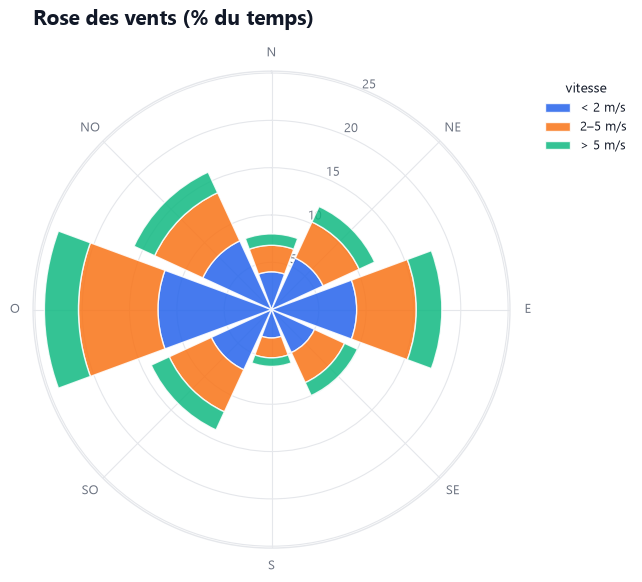

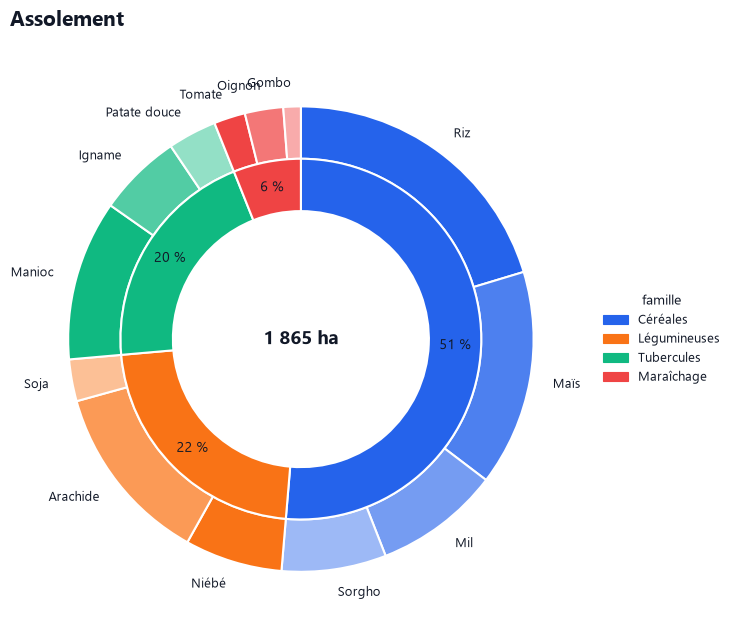

In [21]:
directions = ['N', 'NE', 'E', 'SE', 'S', 'SO', 'O', 'NO']
rose = pd.DataFrame([(d, v, f) for d, base in zip(directions, [4, 6, 9, 5, 3, 7, 12, 8])
                     for v, f in zip(['< 2 m/s', '2–5 m/s', '> 5 m/s'], [base, base * .7, base * .3])],
                    columns=['direction', 'vitesse', 'frequence'])
(Chart(rose, figsize=(6.5, 6.5))
    .polar('direction', 'frequence', group='vitesse', compass=True)
    .title('Rose des vents (% du temps)')
    .tight_layout()
    .show())

(Chart(cultures, figsize=(8, 6.5))
    .donut('surface', labels='culture', group='famille', center_text='1 865 ha')
    .title('Assolement')
    .tight_layout()
    .show())

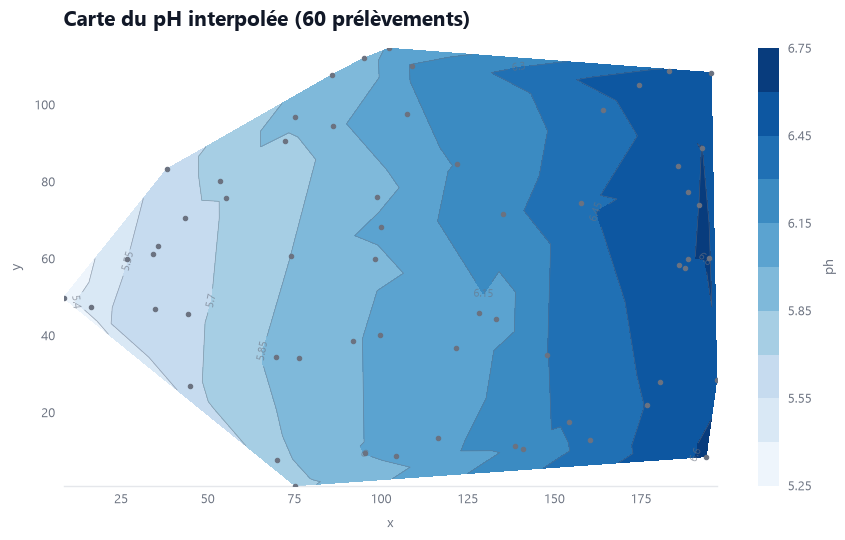

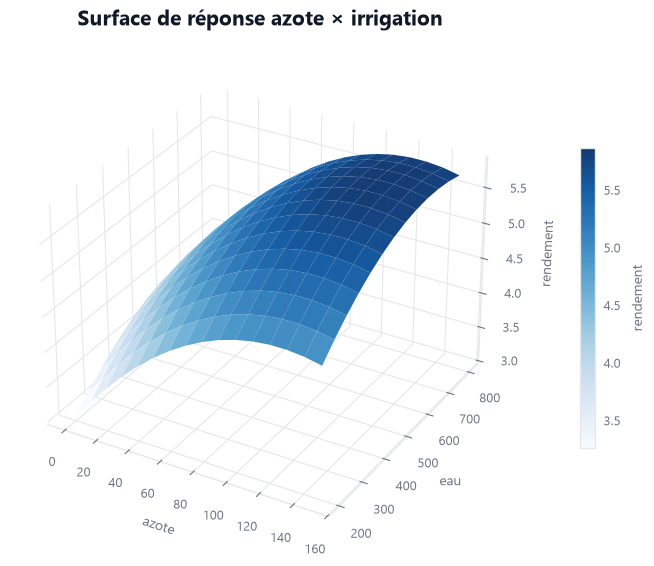

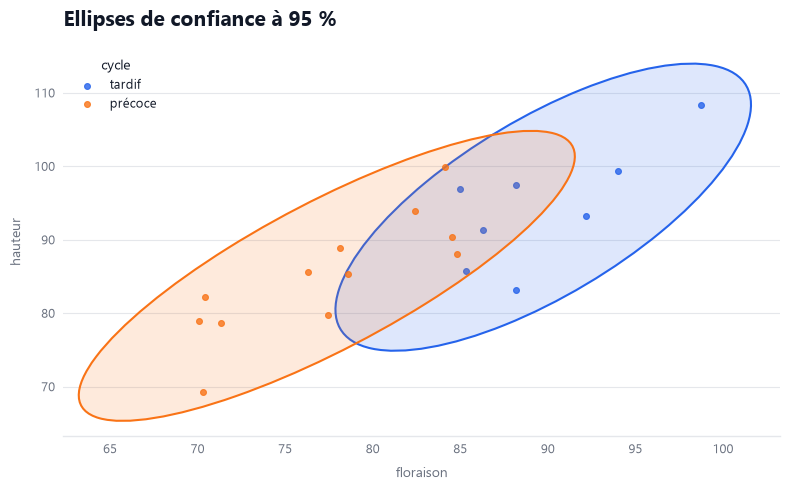

In [22]:
rng = np.random.default_rng(4)
x, y = rng.uniform(0, 200, 60), rng.uniform(0, 120, 60)
champ = pd.DataFrame({'x': x, 'y': y, 'ph': 5.4 + 0.006 * x + rng.normal(0, 0.05, 60)})
(Chart(champ, figsize=(9, 5.5))
    .contour('x', 'y', 'ph', show_points=True)
    .title('Carte du pH interpolée (60 prélèvements)')
    .tight_layout()
    .show())

az, eau = np.meshgrid(np.linspace(0, 150, 16), np.linspace(200, 800, 13))
reponse = pd.DataFrame({'azote': az.ravel(), 'eau': eau.ravel()})
reponse['rendement'] = (2 + 0.03 * reponse['azote'] - 0.00012 * reponse['azote'] ** 2
                        + 0.006 * reponse['eau'] - 0.0000045 * reponse['eau'] ** 2)
(Chart(reponse, figsize=(9, 6.5))
    .surface('azote', 'eau', 'rendement')
    .title('Surface de réponse azote × irrigation')
    .show())

(Chart(caracteres, figsize=(8, 5))
    .confidence_ellipse('floraison', 'hauteur', group='cycle')
    .title('Ellipses de confiance à 95 %')
    .tight_layout()
    .show())

## 8. Climat & sols

Une station **fictive** de climat soudanien (valeurs illustratives).

{'t_moyenne': 27.416666666666668, 'p_totale': 1096.0, 'mois_secs': ['Jan', 'Fév', 'Mar', 'Avr', 'Nov', 'Déc']}


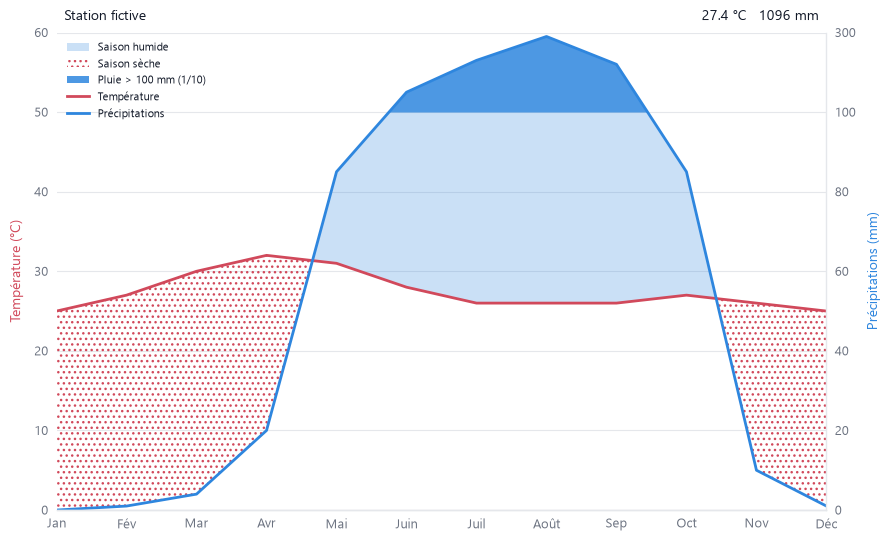

{'excedent': 380.0, 'deficit': 1134.0}


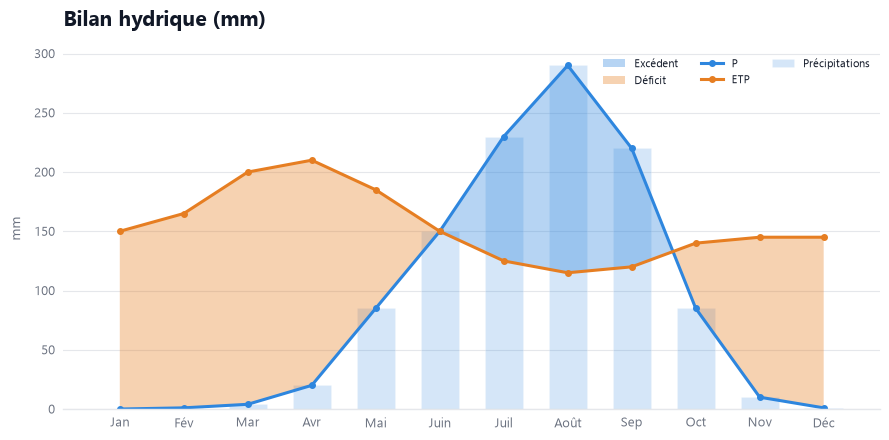

In [23]:
station = pd.DataFrame({
    'mois': ['Jan', 'Fév', 'Mar', 'Avr', 'Mai', 'Juin', 'Juil', 'Août', 'Sep', 'Oct', 'Nov', 'Déc'],
    'temperature': [25, 27, 30, 32, 31, 28, 26, 26, 26, 27, 26, 25],
    'pluie': [0, 1, 4, 20, 85, 150, 230, 290, 220, 85, 10, 1],
    'tmin': [17, 19, 22, 25, 24, 22, 21, 21, 21, 21, 19, 17],
    'etp': [150, 165, 200, 210, 185, 150, 125, 115, 120, 140, 145, 145],
})

chart = (Chart(station, figsize=(9, 5.5))
    .walter_lieth('mois', 'temperature', 'pluie', tmin='tmin', station='Station fictive')
    .tight_layout())
print(chart.climate_summary)
chart.show()

chart = (Chart(station, figsize=(9, 4.5))
    .water_balance('mois', 'pluie', 'etp')
    .title('Bilan hydrique (mm)')
    .tight_layout())
print(chart.water_summary)
chart.show()

{'Tallage': Timestamp('2024-07-07 00:00:00'), 'Floraison': Timestamp('2024-08-17 00:00:00')}


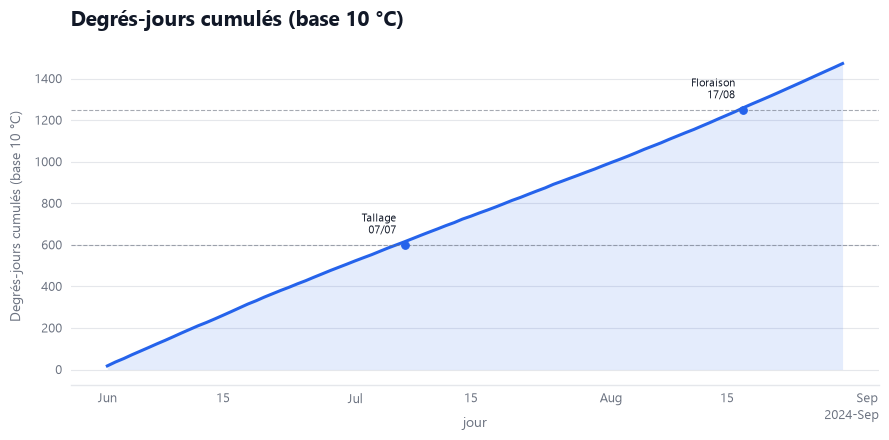

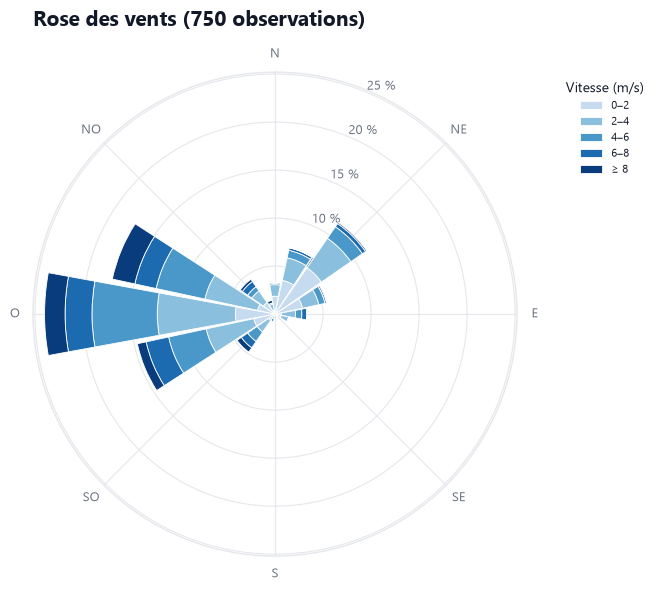

In [24]:
chart = (Chart(meteo, figsize=(9, 4.5))
    .degree_days('jour', 'tmin', 'tmax', base=10, cap=35,
                 stages={'Tallage': 600, 'Floraison': 1250})
    .title('Degrés-jours cumulés (base 10 °C)')
    .tight_layout())
print(chart.stage_dates)
chart.show()

rng = np.random.default_rng(12)
vent_obs = pd.DataFrame({
    'direction': np.concatenate([rng.normal(270, 25, 500), rng.normal(45, 30, 250)]) % 360,
    'vitesse': np.concatenate([rng.gamma(3, 1.4, 500), rng.gamma(2, 1.2, 250)]),
})
(Chart(vent_obs, figsize=(7, 6))
    .wind_rose('direction', 'vitesse')
    .title('Rose des vents (750 observations)')
    .tight_layout()
    .show())

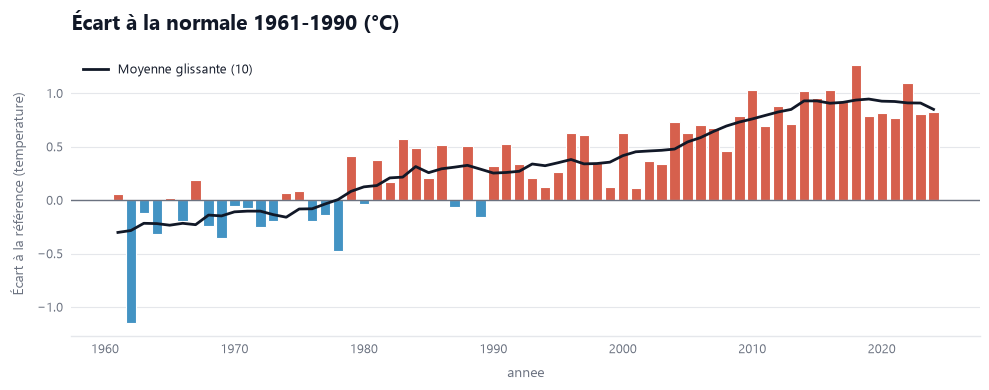

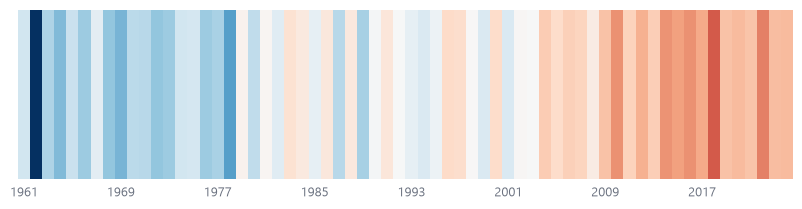

In [25]:
rng = np.random.default_rng(13)
annees = pd.DataFrame({'annee': np.arange(1961, 2025)})
annees['temperature'] = 26.8 + 0.022 * (annees['annee'] - 1961) + rng.normal(0, 0.25, len(annees))

(Chart(annees, figsize=(10, 4))
    .anomaly('annee', 'temperature', baseline=(1961, 1990), window=10)
    .title('Écart à la normale 1961-1990 (°C)')
    .tight_layout()
    .show())

Chart(annees, figsize=(10, 2.2)).climate_stripes('annee', 'temperature').show()

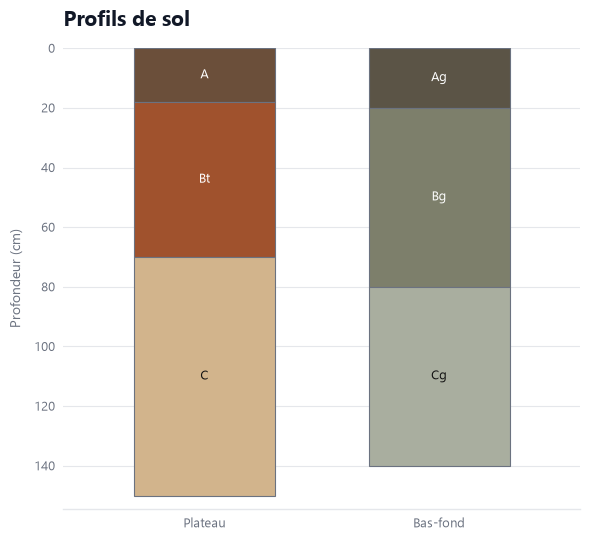

In [26]:
horizons = pd.DataFrame({
    'fosse': ['Plateau'] * 3 + ['Bas-fond'] * 3,
    'horizon': ['A', 'Bt', 'C', 'Ag', 'Bg', 'Cg'],
    'haut': [0, 18, 70, 0, 20, 80],
    'bas': [18, 70, 150, 20, 80, 140],
    'couleur': ['#6b4f3a', '#a0522d', '#d2b48c', '#5b5446', '#7d7f6b', '#a9ae9f'],
})
(Chart(horizons, figsize=(6, 5.5))
    .soil_profile('haut', 'bas', 'horizon', profile='fosse', color='couleur')
    .title('Profils de sol')
    .tight_layout()
    .show())

## 9. Map

Cartes avec l'option `map` (`pip install plutovizu[map]`). Coordonnées réelles des villes, valeurs **illustratives**.

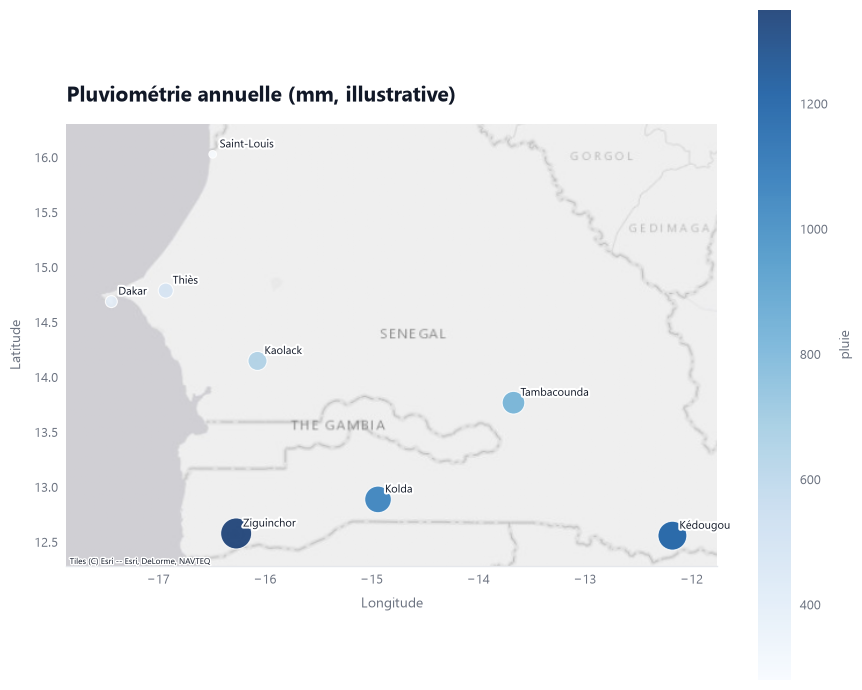

In [27]:
villes = pd.DataFrame({
    'ville': ['Dakar', 'Thiès', 'Saint-Louis', 'Kaolack', 'Tambacounda', 'Kolda', 'Ziguinchor', 'Kédougou'],
    'lon': [-17.44, -16.93, -16.49, -16.07, -13.67, -14.94, -16.27, -12.18],
    'lat': [14.69, 14.79, 16.03, 14.15, 13.77, 12.89, 12.58, 12.56],
    'pluie': [380, 480, 280, 640, 820, 1050, 1350, 1200],
})
(Chart(villes, figsize=(9, 7))
    .map_points('lon', 'lat', value='pluie', size='pluie', labels='ville')
    .title('Pluviométrie annuelle (mm, illustrative)')
    .tight_layout()
    .show())

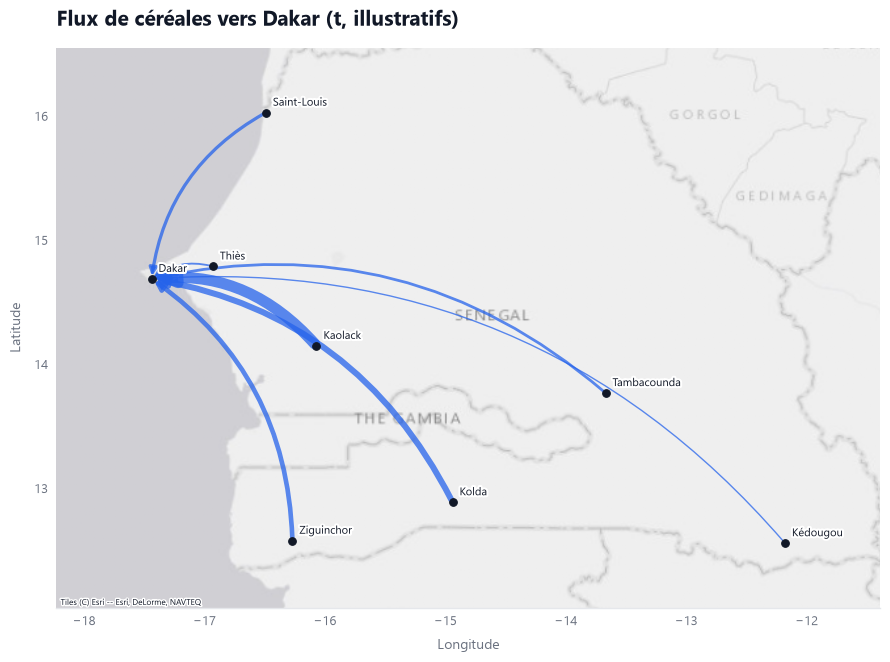

In [28]:
dakar = villes.set_index('ville').loc['Dakar']
flux = (villes[villes['ville'] != 'Dakar']
        .assign(vers='Dakar', lon_d=dakar['lon'], lat_d=dakar['lat'],
                tonnes=[200, 350, 1200, 300, 650, 500, 150]))
(Chart(flux, figsize=(9, 7))
    .flow_map('lon', 'lat', 'lon_d', 'lat_d', weight='tonnes', label_from='ville', label_to='vers')
    .title('Flux de céréales vers Dakar (t, illustratifs)')
    .tight_layout()
    .show())

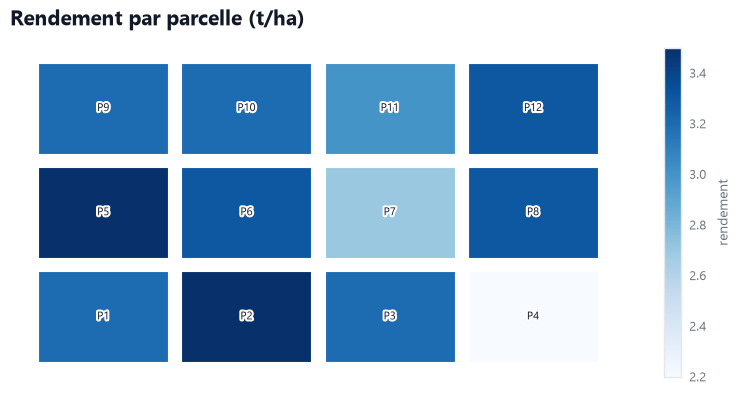

In [29]:
import geopandas as gpd
from shapely.geometry import box

rng = np.random.default_rng(1)
parcelles = gpd.GeoDataFrame(
    {'parcelle': [f'P{i + 1}' for i in range(12)],
     'rendement': (3 + rng.normal(0, 0.6, 12)).round(1)},
    geometry=[box(x * 110, y * 80, x * 110 + 100, y * 80 + 70) for y in range(3) for x in range(4)],
    crs='EPSG:32628')
(Chart(parcelles, figsize=(8, 5))
    .choropleth('rendement', labels='parcelle')
    .title('Rendement par parcelle (t/ha)')
    .tight_layout()
    .show())

## 10. Graphiques seaborn

`chart.seaborn('nom')` donne accès à toutes les fonctions de seaborn ; les plus courantes ont un raccourci (`kde`, `swarm`, `pairplot`, `jointplot`…).

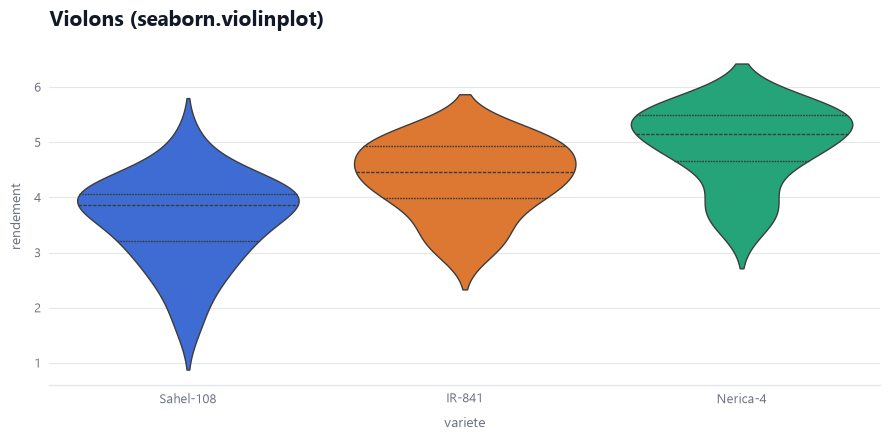

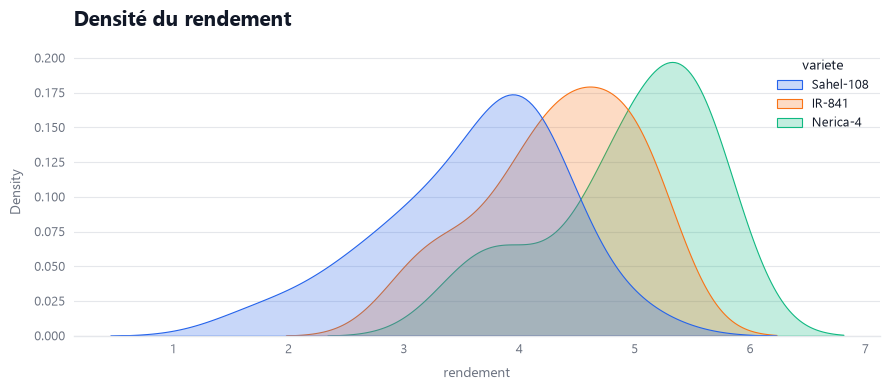

In [30]:
(Chart(essai, figsize=(9, 4.5))
    .seaborn('violinplot', x='variete', y='rendement', hue='variete', inner='quart')
    .title('Violons (seaborn.violinplot)')
    .tight_layout()
    .show())

(Chart(essai, figsize=(9, 4))
    .kde('rendement', hue='variete')
    .title('Densité du rendement')
    .tight_layout()
    .show())

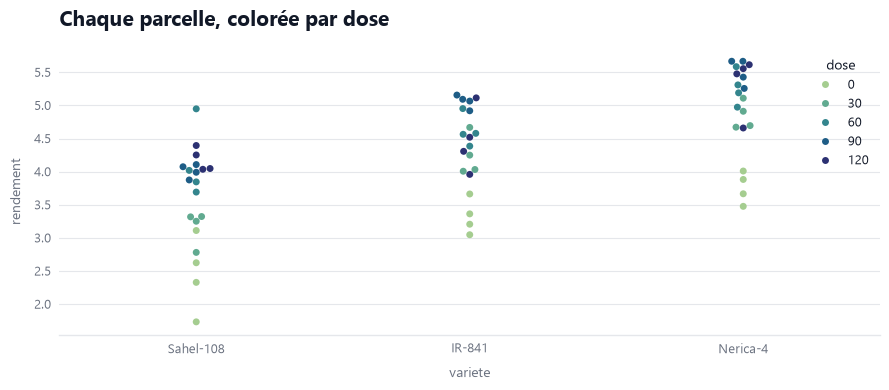

In [31]:
(Chart(essai, figsize=(9, 4))
    .swarm('variete', 'rendement', hue='dose', palette='crest')
    .title('Chaque parcelle, colorée par dose')
    .tight_layout()
    .show())

Les fonctions seaborn à plusieurs panneaux remplacent la figure : `title()` devient le titre général.

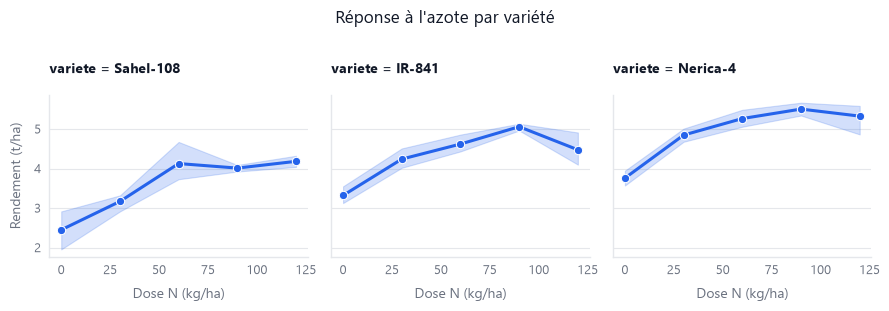

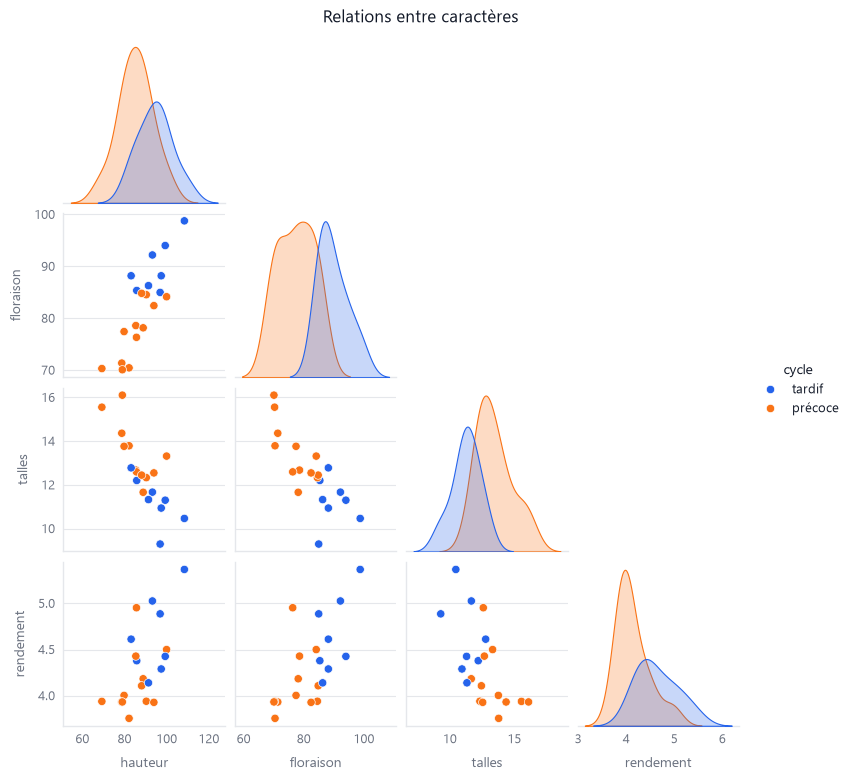

In [32]:
(Chart(essai)
    .seaborn('relplot', x='dose', y='rendement', col='variete', kind='line', marker='o', height=3)
    .title("Réponse à l'azote par variété")
    .labels('Dose N (kg/ha)', 'Rendement (t/ha)')
    .tight_layout()
    .show())

(Chart(caracteres)
    .pairplot(vars=['hauteur', 'floraison', 'talles', 'rendement'], hue='cycle', corner=True, height=1.9)
    .title('Relations entre caractères')
    .show())

## 11. Thèmes

36 thèmes : 15 maison (dont prezi), 5 styles seaborn et 16 morethemes (paquet optionnel). `theme_context` limite un thème à un bloc `with`.

In [33]:
{source: list_themes(source) for source in ['plutovizu', 'seaborn', 'morethemes']}

{'plutovizu': ['accessible',
  'arctic',
  'blueprint',
  'editorial',
  'forest',
  'ink',
  'neon',
  'ocean',
  'paper',
  'pastel',
  'pluto',
  'prezi',
  'sahel',
  'sunset',
  'terminal'],
 'seaborn': ['seaborn-dark',
  'seaborn-darkgrid',
  'seaborn-ticks',
  'seaborn-white',
  'seaborn-whitegrid'],
 'morethemes': ['darker',
  'ebonis',
  'economist',
  'ft',
  'greenwave',
  'lighter',
  'lumen',
  'minimal',
  'monoblue',
  'nature',
  'nord',
  'retro',
  'urban',
  'vscode-dark',
  'wsj',
  'yellowish']}

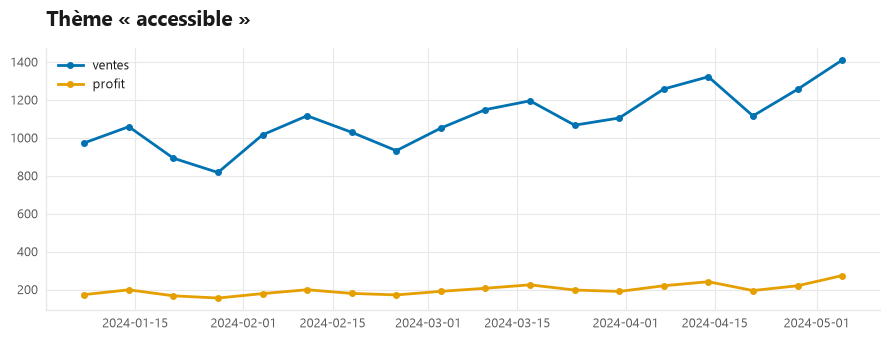

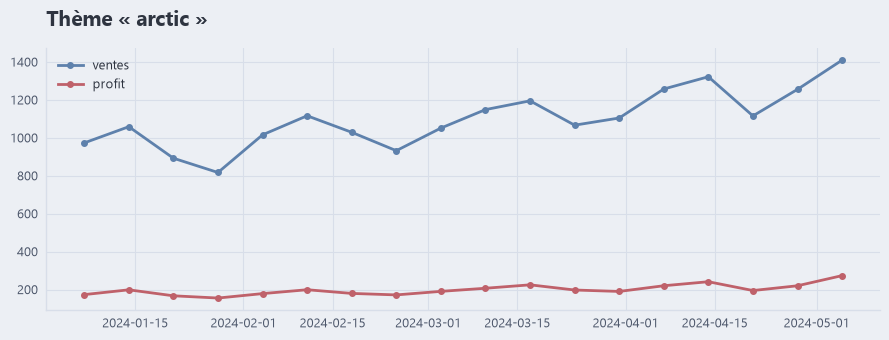

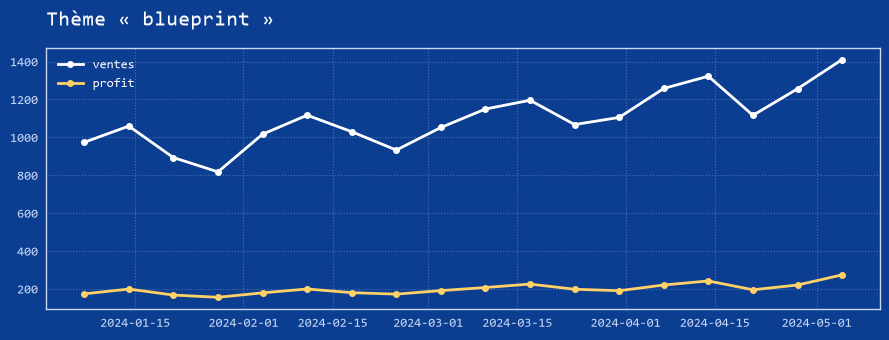

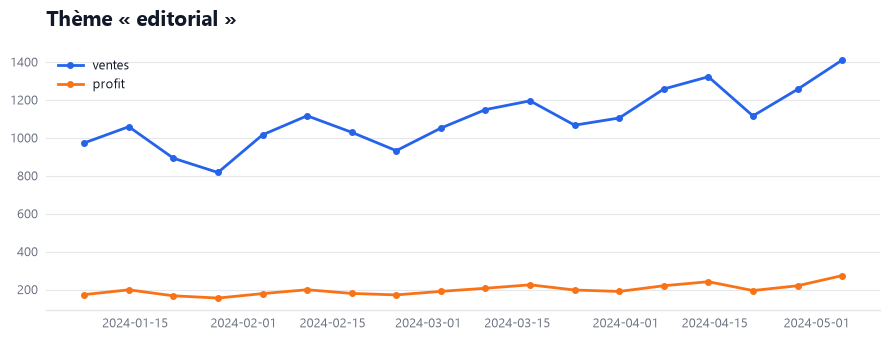

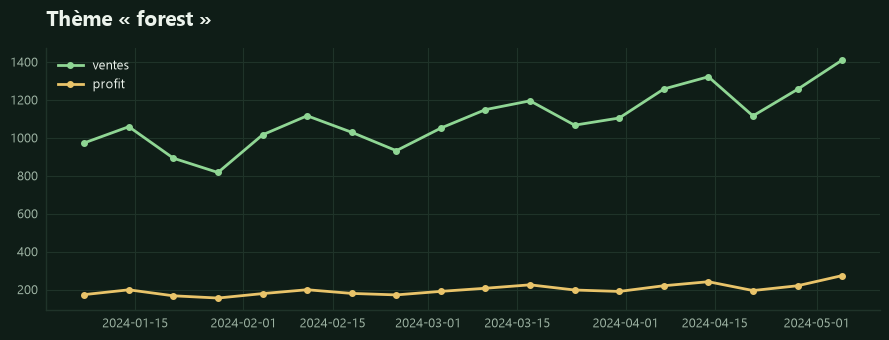

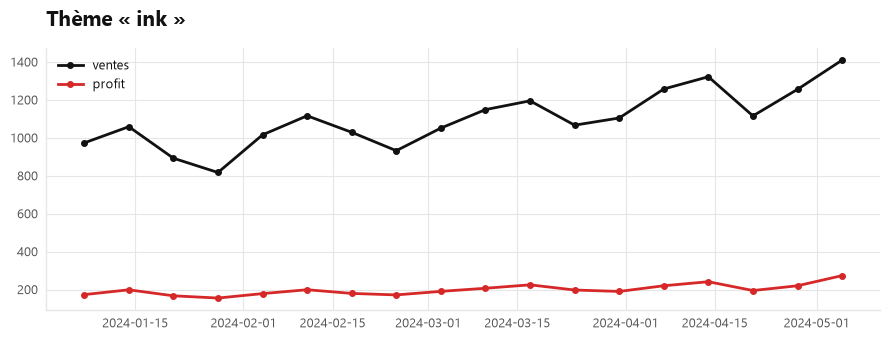

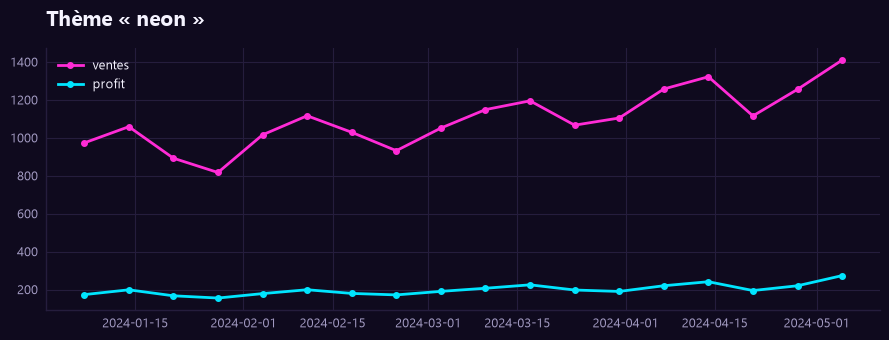

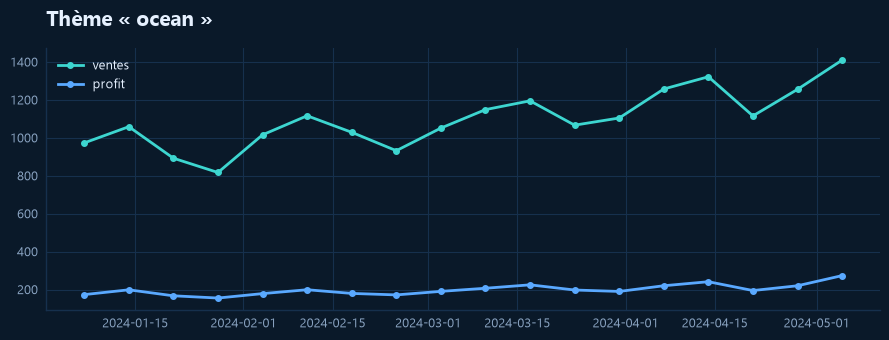

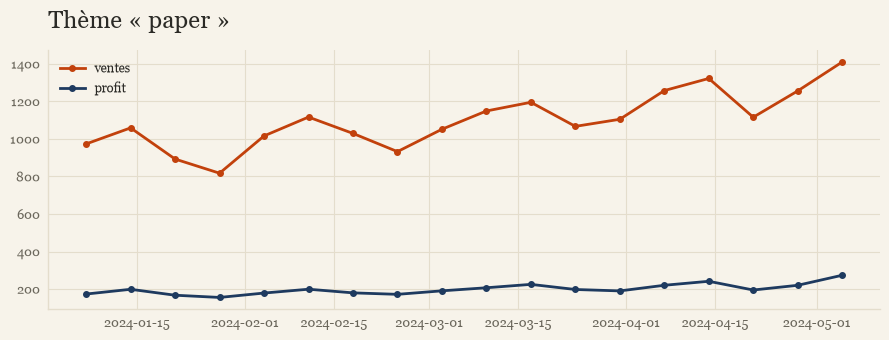

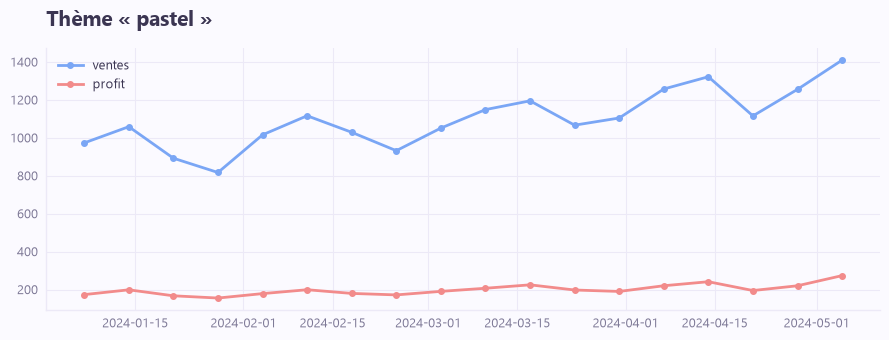

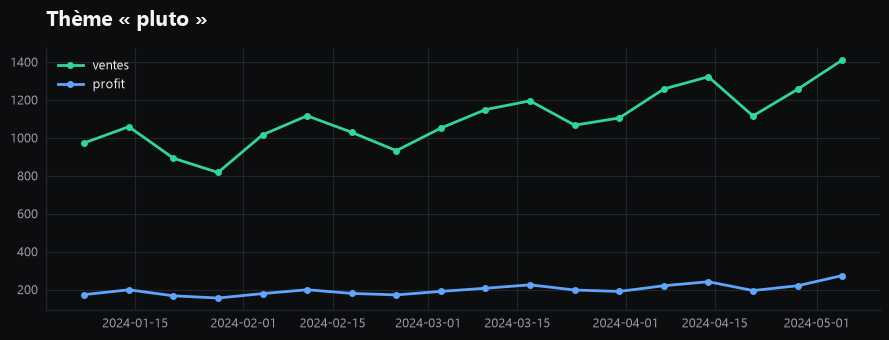

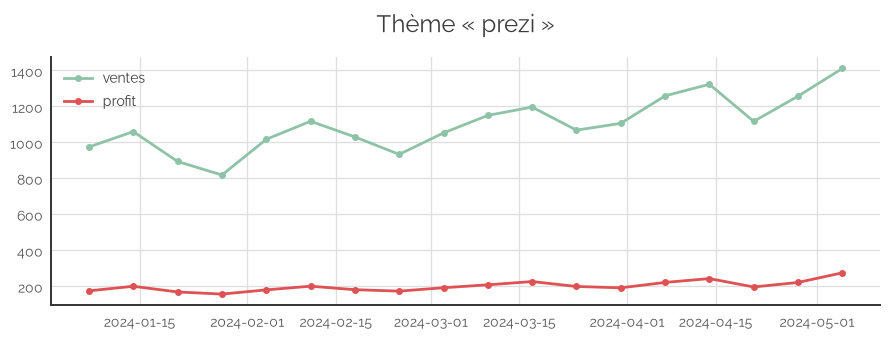

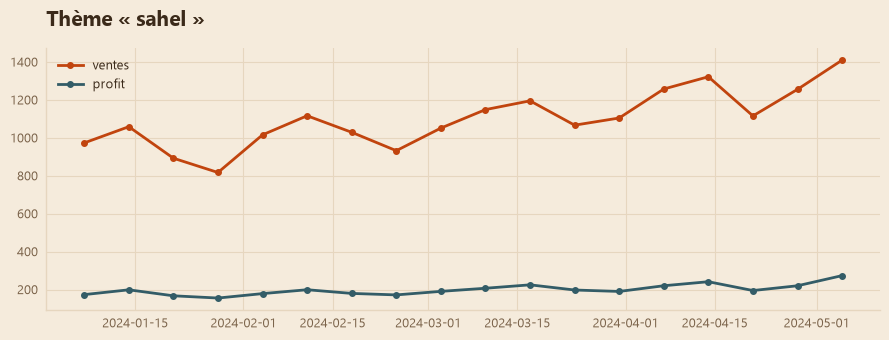

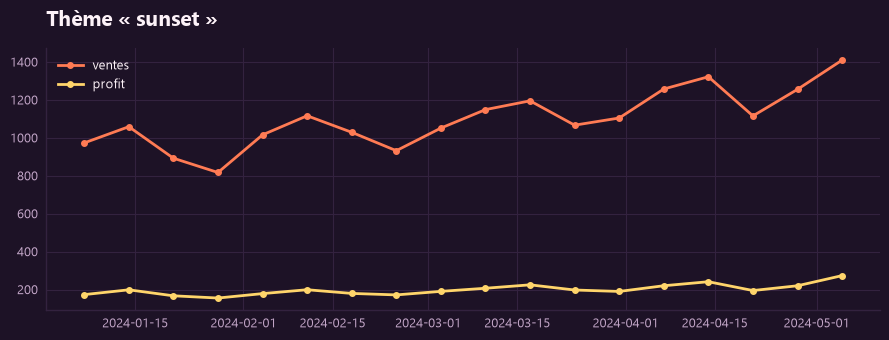

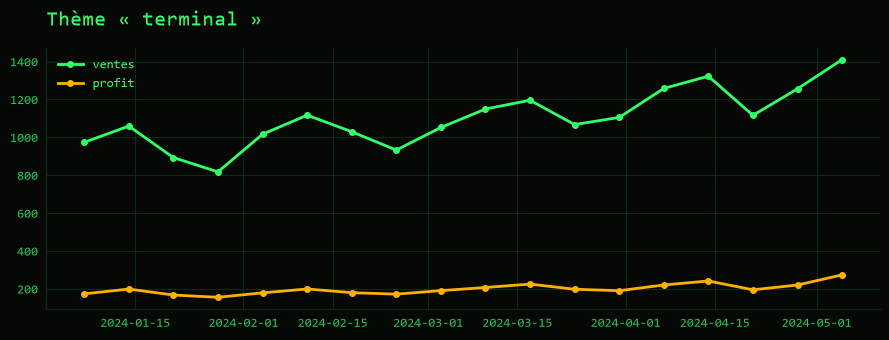

In [34]:
for nom in list_themes('plutovizu'):
    with theme_context(nom):
        (Chart(hebdo, figsize=(9, 3.5))
            .line('date', ['ventes', 'profit'], marker='o', markersize=4)
            .title(f'Thème « {nom} »')
            .set_legend()
            .tight_layout()
            .show())

Quelques styles seaborn et thèmes morethemes (les seconds téléchargent leur police au premier usage) :

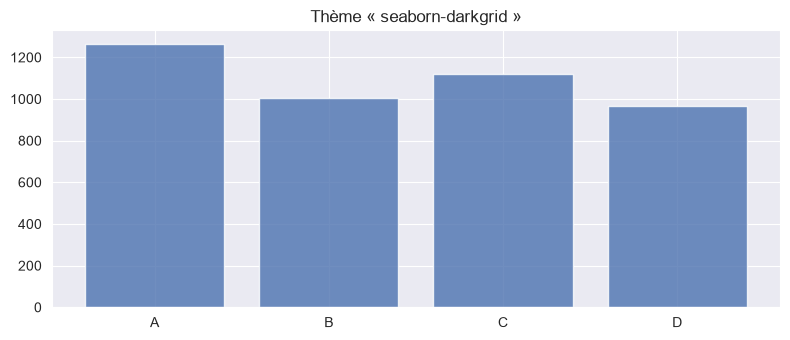

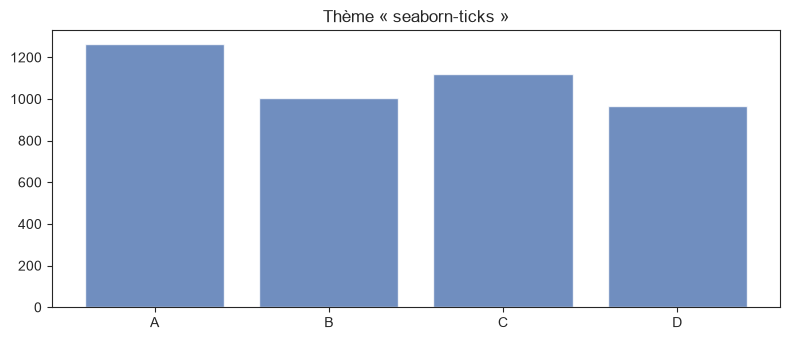

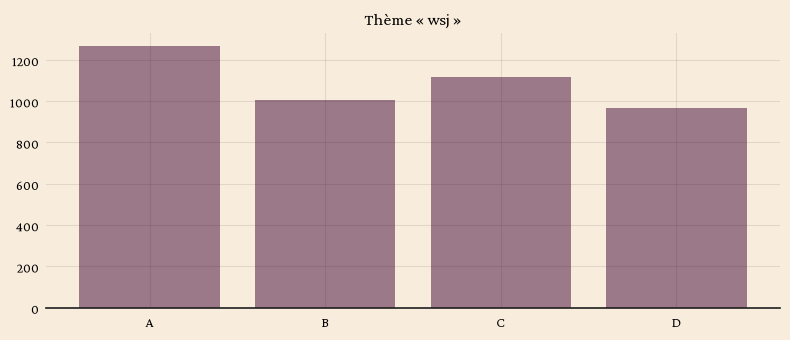

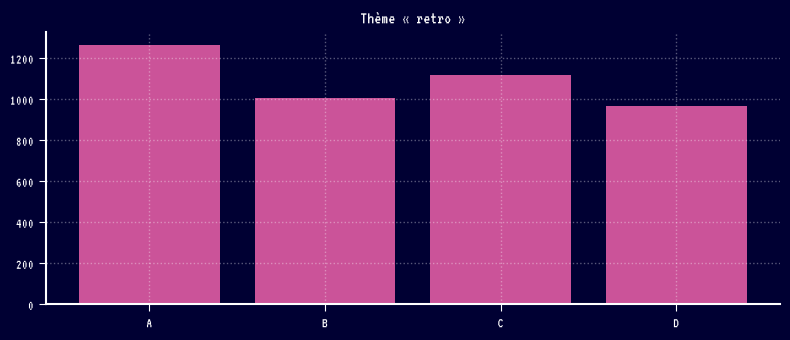

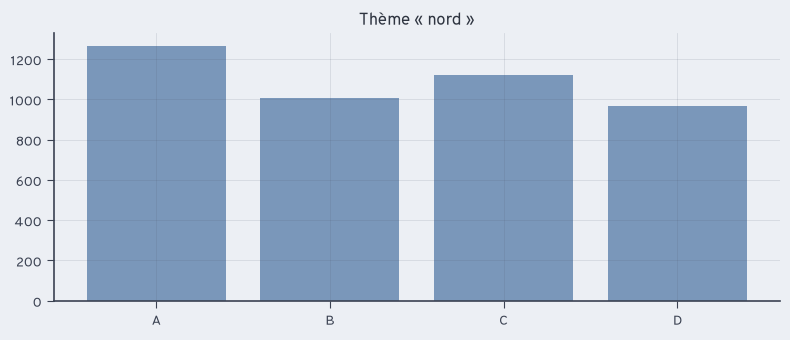

In [35]:
for nom in ['seaborn-darkgrid', 'seaborn-ticks', 'wsj', 'retro', 'nord']:
    with theme_context(nom):
        (Chart(par_categorie, figsize=(8, 3.5))
            .bar('categorie', 'ventes')
            .title(f'Thème « {nom} »')
            .tight_layout()
            .show())

`context` adapte la taille du texte au support (`'paper'`, `'notebook'`, `'talk'`, `'poster'`). `set_theme` applique un thème à toute la session ; `set_theme(None)` revient au style matplotlib.

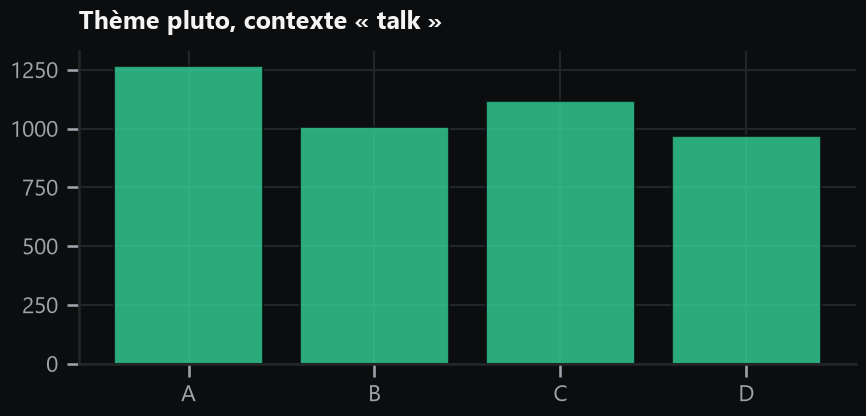

In [36]:
set_theme('pluto', context='talk')
(Chart(par_categorie, figsize=(9, 4.5))
    .bar('categorie', 'ventes')
    .title('Thème pluto, contexte « talk »')
    .tight_layout()
    .show())
set_theme()   # retour au thème par défaut (editorial)

## 12. Palettes de couleurs

`set_colors` applique une palette à **ce** graphique (sans changer le thème des suivants).

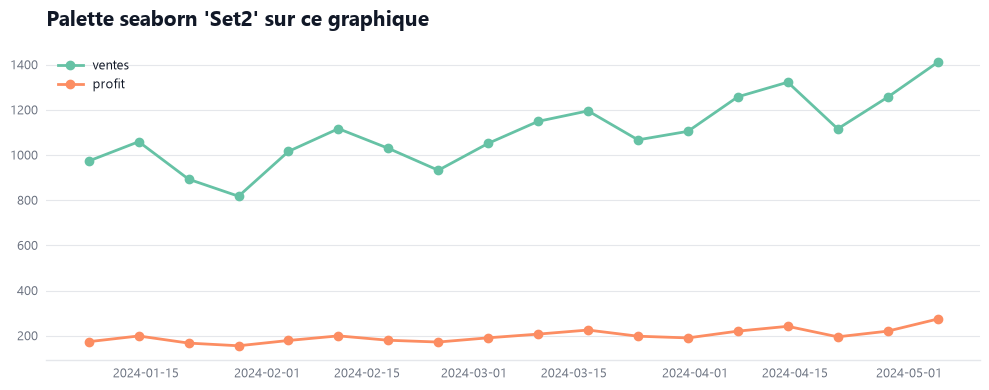

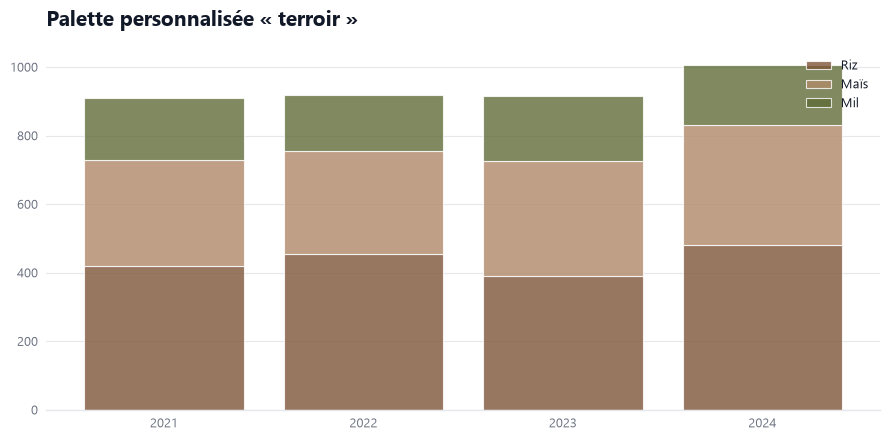

In [37]:
(Chart(hebdo, figsize=(10, 4))
    .set_colors('Set2')
    .line('date', ['ventes', 'profit'])
    .title("Palette seaborn 'Set2' sur ce graphique")
    .set_legend()
    .tight_layout()
    .show())

(Chart(production, figsize=(9, 4.5))
    .create_custom_palette('terroir', ['#7f5539', '#b08968', '#606c38'])
    .bar('annee', ['Riz', 'Maïs', 'Mil'], stacked=True)
    .title('Palette personnalisée « terroir »')
    .tight_layout()
    .show())

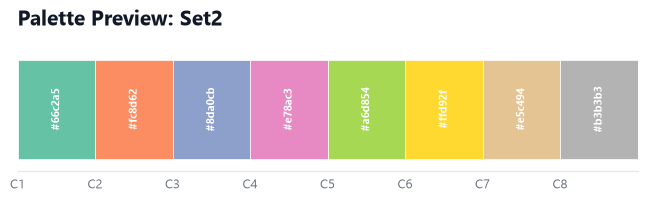

In [38]:
Chart(ventes, figsize=(8, 1.6)).preview_palette('Set2').show()

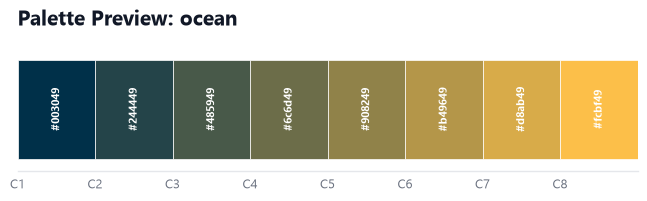

In [39]:
(Chart(ventes, figsize=(8, 1.6))
    .generate_gradient_palette('ocean', '#003049', '#fcbf49', n_colors=8)
    .preview_palette('ocean')
    .show())

## 13. Polices

`font()` modifie la police globale de matplotlib : on l'isole dans `plt.rc_context()` pour ne pas affecter les graphiques suivants.

In [40]:
get_fonts(pattern='Times')

['Times New Roman']

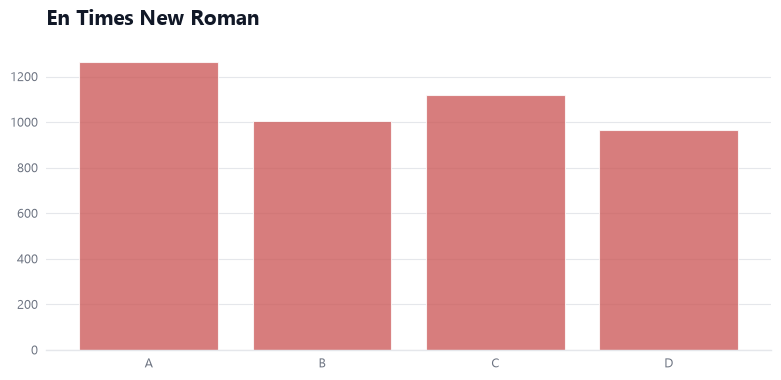

In [41]:
with plt.rc_context():
    (Chart(par_categorie, figsize=(8, 4))
        .font('Times New Roman', size=13)
        .bar('categorie', 'ventes', color='indianred')
        .title('En Times New Roman')
        .tight_layout()
        .show())

## 14. Export

Appeler `save()` **avant** `show()` : `show()` ferme la figure pour libérer la mémoire.

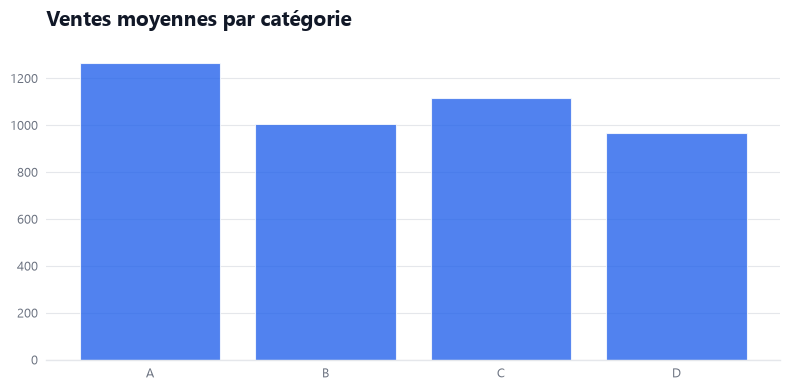

Enregistré : C:\Users\ORDINA~1\AppData\Local\Temp\ventes_par_categorie.png (19 Ko)


In [42]:
fichier = Path(tempfile.gettempdir()) / 'ventes_par_categorie.png'

(Chart(par_categorie, figsize=(8, 4), theme='editorial')
    .bar('categorie', 'ventes')
    .title('Ventes moyennes par catégorie')
    .tight_layout()
    .save(fichier, dpi=150)
    .show())
set_theme()   # retour au thème par défaut
print(f'Enregistré : {fichier} ({fichier.stat().st_size // 1024} Ko)')